<img src="https://drive.google.com/uc?export=view&id=17XA0hEjH3jdhyh2UPzDZLdpYXOn6Dzt4" width="1000px" height="250px" style="object-fit: cover;">

# **Sistema de alarma temprana y segmentación de riesgo renal**
## Integrantes:


*   Sol Valeria Arias Rojas 2251518
*   Ángel Javier Corzo Arias 2250926
*   Elías David Arrieta Olivero 2250952



#### Motivación, Problema y Datos
##### **Problema**
La enfermedad renal crónica (ERC) es una condición que avanza de forma silencios, ya que en sus etapas iniciales no presenta síntomas claros, por lo que en muchos casos se detectan cuando ya esta muy avanzado el daño renal. Sin embargo, gran parte de la información necesaria para sospechar de un riesgo elevado ya está disponible en examen de laboratorio y en datos que se recogen en un chequeo médico de rutina.
Este proyecto busca aprovechar esos datos para construir un sistema que estime el riesgo de ERC de un paciente e identificar que factores clinicos estan mas relacionados con este riesgo.

##### **Origen**
El dataset es **Chronic Kidney Disease Risk Prediction Dataset**. Contiene 50000 registros de pacientes sintéticos, como 40 variables que incluyen:


*   Datos demográficos
*   Medidas corporales
*   Indicadores clínicos
*   Hábitos de vida
*   Historial médico y familiar
*   Hábitos de vida
*   Un score y una categoría de riesgo de ERC
##### **Desafios**



1. **Los pacientes son sintéticos.** Los patrones observados son una aproximación al
   comportamiento clínico esperado, no evidencia epidemiológica. Ningún resultado de este
   trabajo puede interpretarse como hallazgo médico.
2. **`CKD_Risk_Score` es una variable generada, no medida.** Si fue producida por una
   fórmula determinista a partir de las demás columnas, un modelo suficientemente flexible
   puede recuperar esa fórmula y arrojar métricas casi perfectas que no significan nada.
3. **El dataset presenta nulos inyectados a propósito**, simulando la incompletitud de
   los datos clínicos reales. Esto lo tratamos como parte del problema, no como un defecto.

##### Justificación de la ML
El riesgo de Enfermedad Renal Crónica no depende de una sola variable sino de la combinación de múltiples factores clínicos y de estilo de vida actuando en conjunto.
Machine Learning permite aprender esos patrones combinados automáticamente, escalar a los 50,000 pacientes del dataset, y priorizar qué variables más influyen en el riesgo.

## Preparación y selección de variables

### Librerias

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Carga de dataset

In [ ]:
dataset= kagglehub.dataset_download("mobeenfatimah/chronic-kidney-disease-risk-prediction-dataset")
archivos=os.listdir(dataset)
print(archivos)
ruta=os.path.join(dataset,archivos[0])
df=pd.read_csv(ruta)

100%|██████████| 2.57M/2.57M [00:00<00:00, 56.2MB/s]

Extracting files...


['chronic_kidney_disease_risk_prediction_dataset.csv']


### Inspección

#### Shape y Columnas

In [ ]:
print("Shape del dataset:\n", df.shape)
print("Columnas del dataset:\n", df.columns)


Shape del dataset:
 (50000, 40)
Columnas del dataset:
 Index(['Patient_ID', 'Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg',
       'BMI', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic',
       'Blood_Glucose', 'Serum_Creatinine', 'Blood_Urea', 'eGFR', 'Albumin',
       'Hemoglobin', 'Sodium', 'Potassium', 'Heart_Rate', 'Smoking_Status',
       'Alcohol_Consumption', 'Physical_Activity_Level',
       'Exercise_Hours_Per_Week', 'Daily_Water_Intake_L', 'Daily_Salt_Intake',
       'Sleep_Hours', 'Stress_Level', 'Diet_Quality', 'Family_History_CKD',
       'Diabetes', 'Hypertension', 'Heart_Disease', 'Kidney_Stone_History',
       'Medication_Adherence', 'Work_Type', 'Residence_Type',
       'Air_Pollution_Exposure', 'CKD_Risk_Score', 'AI_Health_Recommendation',
       'Doctor_Consultation_Needed', 'CKD_Risk'],
      dtype='object')


In [ ]:
df.head()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Glucose,...,Heart_Disease,Kidney_Stone_History,Medication_Adherence,Work_Type,Residence_Type,Air_Pollution_Exposure,CKD_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,CKD_Risk
0,1,32.0,Male,Singapore,163.7,125.8,46.9,103,103,179.8,...,No,No,Average,Self-Employed,Urban,Low,86,Immediate Medical Attention,Yes,High
1,2,31.0,Male,Brazil,155.6,60.5,25.0,167,76,97.5,...,No,No,Average,Self-Employed,Urban,Medium,70,Immediate Medical Attention,Yes,High
2,3,44.0,Other,India,155.0,88.7,36.9,99,98,158.9,...,No,No,Good,Student,Rural,High,79,Strict Blood Pressure Management,Yes,High
3,4,36.0,Female,France,167.0,55.4,19.9,123,107,144.3,...,No,No,Good,Private,Rural,High,47,Reduce Salt Intake,Yes,Moderate
4,5,NaN,Male,South Africa,NaN,NaN,30.8,123,92,NaN,...,No,No,NaN,Private,Urban,High,92,Consult Nephrologist Immediately,Yes,High


#### Deteccion de valores nulos y Tipo de dato

In [ ]:
resumen_info = pd.DataFrame({
    'Tipo de dato': df.dtypes,
    'No nulos': df.notnull().sum(),
    'Nulos': df.isnull().sum(),
    'Porcentaje nulos (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(resumen_info)

,Tipo de dato,No nulos,Nulos,Porcentaje nulos (%)
Patient_ID,int64,50000,0,0.00
Age,float64,48901,1099,2.20
Gender,object,50000,0,0.00
Country,object,50000,0,0.00
Height_cm,float64,47098,2902,5.80
Weight_kg,float64,46621,3379,6.76
BMI,float64,50000,0,0.00
Blood_Pressure_Systolic,int64,50000,0,0.00
Blood_Pressure_Diastolic,int64,50000,0,0.00
Blood_Glucose,float64,47491,2509,5.02


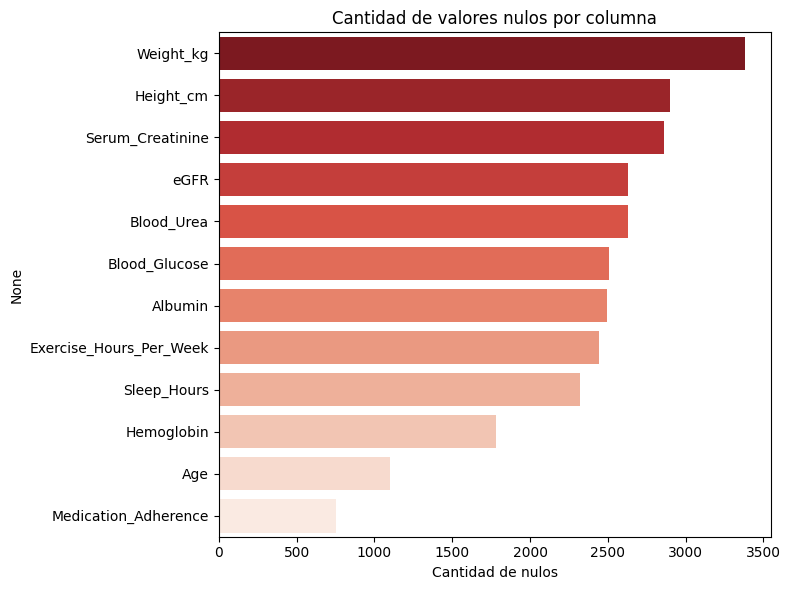

In [ ]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=nulos.values, y=nulos.index, hue=nulos.index, palette='Reds_r', legend=False)
plt.title('Cantidad de valores nulos por columna')
plt.xlabel('Cantidad de nulos')
plt.tight_layout()
plt.show()

#### Variable Objetivo: CKD_Risk
CKD_Risk es la variable categórica que se busca predecir en este proyecto. Clasifica a cada paciente en uno de tres niveles de riesgo de enfermedad renal crónica: Low, Moderate, High. Esta categoría se deriva del CKD_Risk_Score, por lo que ambas columnas están  relacionadas
y no pueden usarse como variables predictoras entre sí.

Frecuencia por categoría:


,Frecuencia
CKD_Risk,
High,38823
Moderate,10862
Low,315



Porcentaje por categoría:


,Porcentaje (%)
CKD_Risk,
High,77.65
Moderate,21.72
Low,0.63


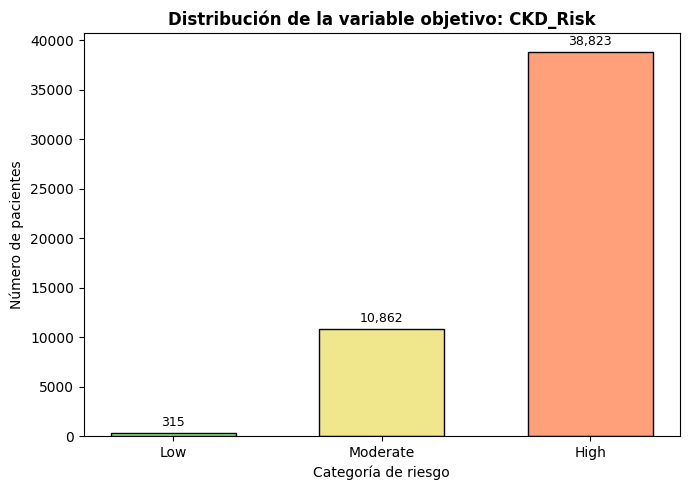

In [ ]:
conteo = df['CKD_Risk'].value_counts()
print("Frecuencia por categoría:")
display(conteo.to_frame(name='Frecuencia'))
porcentaje = df['CKD_Risk'].value_counts(normalize=True) * 100
print("\nPorcentaje por categoría:")
display(porcentaje.round(2).to_frame(name='Porcentaje (%)'))
categorias = ['Low', 'Moderate', 'High']
conteo = df['CKD_Risk'].value_counts().reindex(categorias)
colores = ["lightgreen", "khaki", "lightsalmon"]

plt.figure(figsize=(7, 5))
barras = plt.bar(categorias, conteo.values, color=colores, edgecolor='black', width=0.6)
plt.title("Distribución de la variable objetivo: CKD_Risk", fontsize=12, fontweight='bold')
plt.ylabel("Número de pacientes")
plt.xlabel("Categoría de riesgo")

for barra in barras:
    yval = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2.0,
        yval + (max(conteo.values) * 0.01),
        f'{int(yval):,}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

Frecuencia por categoría:


,Frecuencia
Low + Moderate,11177
High,38823



Porcentaje por categoría:


,Porcentaje (%)
Low + Moderate,22.35
High,77.65


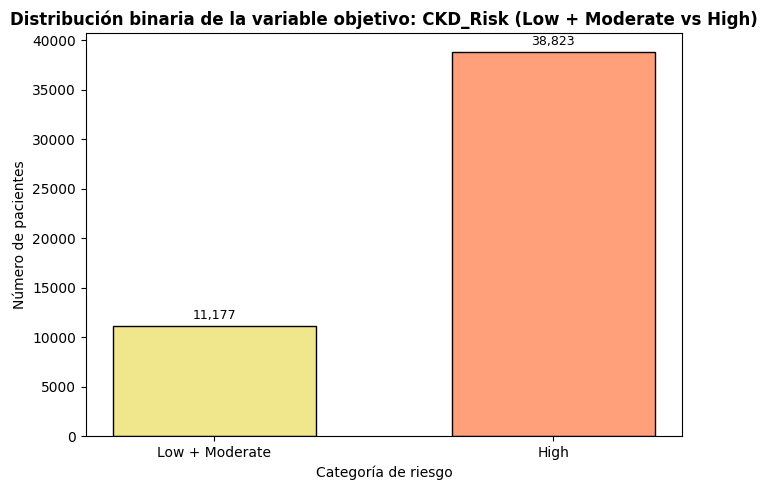

In [ ]:
conteo = df['CKD_Risk'].value_counts()
conteo = pd.Series({'Low + Moderate': conteo['Low'] + conteo['Moderate'],
                    'High': conteo['High']})
porcentaje = conteo / conteo.sum() * 100

print("Frecuencia por categoría:")
display(conteo.to_frame(name='Frecuencia'))
print("\nPorcentaje por categoría:")
display(porcentaje.round(2).to_frame(name='Porcentaje (%)'))

categorias = list(conteo.index)
colores = ["khaki", "lightsalmon"]

plt.figure(figsize=(7, 5))
barras = plt.bar(categorias, conteo.values, color=colores, edgecolor='black', width=0.6)
plt.title("Distribución binaria de la variable objetivo: CKD_Risk (Low + Moderate vs High)",
          fontsize=12, fontweight='bold')
plt.ylabel("Número de pacientes")
plt.xlabel("Categoría de riesgo")

for barra in barras:
    yval = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2.0,
        yval + (max(conteo.values) * 0.01),
        f'{int(yval):,}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

#### Conclusión de la distribución: CKD_Risk

La variable CKD_Risk esta fuertemente desbalanceada: el 77.65% de los pacientes están en la categoría "High", el 21.72% en "Moderate" y apenas el 0,63% en "Low". Este desbalance extremo hacia la categoría de riesgo alto obliga a usar métricas como F1-macro en la fase de modelado, ya que un modelo que prediga siempre 'High' ya acertaría el 77.65% de las veces.

Tabla con estadísticas descriptivas

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Patient_ID,50000.0,25000.500000,14433.901067,1.0,12500.75,25000.50,37500.25,50000.0
Age,48901.0,54.046073,21.121412,18.0,36.00,54.00,72.00,90.0
Height_cm,47098.0,169.967941,14.435806,145.0,157.40,170.10,182.40,195.0
Weight_kg,46621.0,87.548510,24.513469,45.0,66.40,87.60,108.80,130.0
BMI,50000.0,30.832196,10.124095,11.9,22.80,30.00,37.50,61.6
Blood_Pressure_Systolic,50000.0,134.920400,26.192458,90.0,112.00,135.00,157.00,180.0
Blood_Pressure_Diastolic,50000.0,85.049200,14.706758,60.0,72.00,85.00,98.00,110.0
Blood_Glucose,47491.0,144.648542,43.322345,70.0,107.20,144.40,182.40,220.0
Serum_Creatinine,47136.0,2.751067,1.299701,0.5,1.63,2.74,3.88,5.0
Blood_Urea,47370.0,50.025968,23.005393,10.0,30.10,50.10,69.80,90.0


### Seleccion de variables relevantes


##### Separacion de variables numericas y categoricas

In [ ]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop(
    ['Patient_ID', 'CKD_Risk_Score'], errors='ignore'
)
cat_cols = df.select_dtypes(include=['object']).columns.drop(
    ['CKD_Risk', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed'],
    errors='ignore'
).tolist()
print(f'Categóricas evaluadas: {len(cat_cols)}')

Categóricas evaluadas: 17


##### Correlación de las variables numéricas contra el score de riesgo

In [ ]:
correlaciones = df[num_cols].corrwith(df['CKD_Risk_Score']).abs()
ranking_numericas = correlaciones.sort_values(ascending=False)
top_numericas = ranking_numericas.head(6).index


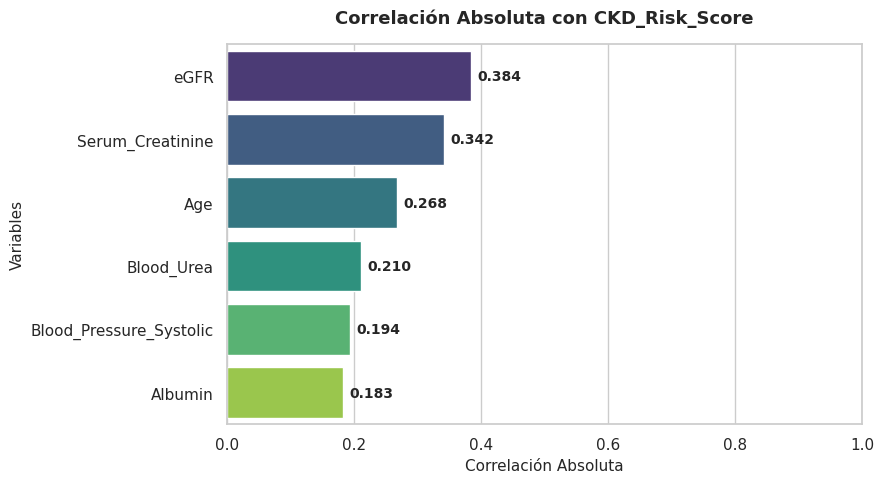

In [ ]:
top_6_series = ranking_numericas.head(6)
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x=top_6_series.values,
    y=top_6_series.index,
    hue=top_6_series.index,
    palette="viridis",
    legend=False
)

plt.title("Correlación Absoluta con CKD_Risk_Score", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Correlación Absoluta", fontsize=11)
plt.ylabel("Variables", fontsize=11)
plt.xlim(0, 1)

for index, value in enumerate(top_6_series.values):
    ax.text(value + 0.01, index, f"{value:.3f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

#### Promedio del score de riesgo por categoría


### Variables seleccionadas


*   Numericas: por correlacion
*   Categoricas: por diferencia de promedios

In [ ]:
diferencias = {}
for col in cat_cols:
    promedios = df.groupby(col)['CKD_Risk_Score'].mean()
    diferencias[col] = promedios.max() - promedios.min()
ranking_cat = pd.DataFrame({
    'Diferencia': pd.Series(diferencias)
}).sort_values(by='Diferencia', ascending=False)

UMBRAL = 5.0
ranking_cat['Cumple_Regla'] = ranking_cat['Diferencia'] >= UMBRAL

display(ranking_cat)

top_categoricas = ranking_cat[ranking_cat['Cumple_Regla']].head(4).index
variables_seleccionadas = list(top_numericas) + list(top_categoricas)
print("Variables seleccionadas:")
print(variables_seleccionadas)
df_General = df[variables_seleccionadas]

,Diferencia,Cumple_Regla
Hypertension,7.166054,True
Diabetes,7.046852,True
Family_History_CKD,7.008477,True
Smoking_Status,5.501965,True
Kidney_Stone_History,5.489017,True
Diet_Quality,4.835496,False
Physical_Activity_Level,4.560184,False
Medication_Adherence,4.535912,False
Heart_Disease,4.532617,False
Stress_Level,3.709956,False


Variables seleccionadas:
['eGFR', 'Serum_Creatinine', 'Age', 'Blood_Urea', 'Blood_Pressure_Systolic', 'Albumin', 'Hypertension', 'Diabetes', 'Family_History_CKD', 'Smoking_Status']


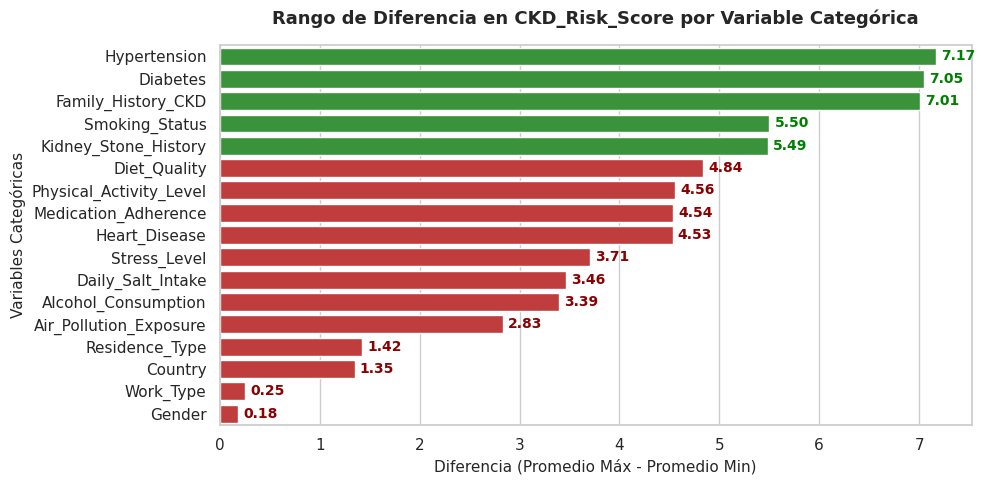

In [ ]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

colores = ['#2ca02c' if cumple else '#d62728' for cumple in ranking_cat['Cumple_Regla']]

ax = sns.barplot(
    x=ranking_cat['Diferencia'],
    y=ranking_cat.index,
    hue=ranking_cat.index,
    palette=colores,
    legend=False
)

plt.title("Rango de Diferencia en CKD_Risk_Score por Variable Categórica", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Diferencia (Promedio Máx - Promedio Min)", fontsize=11)
plt.ylabel("Variables Categóricas", fontsize=11)

for index, (value, cumple) in enumerate(zip(ranking_cat['Diferencia'], ranking_cat['Cumple_Regla'])):
    color_texto = "green" if cumple else "darkred"
    ax.text(value + 0.05, index, f"{value:.2f}", va="center", fontsize=10, fontweight="bold", color=color_texto)

plt.tight_layout()
plt.show()

## Calidad

#### Verificar duplicados exactos

In [ ]:
duplicados_totales = df.duplicated().sum()
print(f"Filas exactamente idénticas: {duplicados_totales}")

Filas exactamente idénticas: 0


Se verificó la existencia de filas exactamente idénticas y no se encontró ninguna, lo que descarta errores de carga o de concatenación al construir el dataset.

#### Verificar Nulos

In [ ]:
nulos = df_General.isnull().sum()
porcentaje_nulos = (nulos / len(df_General)) * 100

resumen_nulos = pd.DataFrame({
    'columna': df_General.columns,
    'valores_nulos': nulos.values,
    'porcentaje_nulos': porcentaje_nulos.values,
    'tipo_dato': df_General.dtypes.values
})
resumen_nulos = resumen_nulos[resumen_nulos['valores_nulos'] > 0].sort_values(
    'porcentaje_nulos', ascending=False
)
display(resumen_nulos)

,columna,valores_nulos,porcentaje_nulos,tipo_dato
1,Serum_Creatinine,2864,5.728,float64
0,eGFR,2631,5.262,float64
3,Blood_Urea,2630,5.260,float64
5,Albumin,2496,4.992,float64
2,Age,1099,2.198,float64


#### Imputacion

In [ ]:
# 1. Romper el vínculo con la vista original para eliminar la advertencia
df_General = df_General.copy()

print("Nulos iniciales:", df_General.isnull().sum().sum())

# 2. Imputar columnas numéricas con la mediana
for col in df_General.select_dtypes(include=['number']).columns:
    df_General[col] = df_General[col].fillna(df_General[col].median())

# 3. Imputar columnas categóricas con la moda
for col in df_General.select_dtypes(exclude=['number']).columns:
    df_General[col] = df_General[col].fillna(df_General[col].mode()[0])

print("Nulos restantes:", df_General.isnull().sum().sum())

Nulos iniciales: 11720
Nulos restantes: 0


Estrategia de imputación. Las columnas con valores nulos (Serum_Creatinine 5.73%, eGFR 5.26%, Blood_Urea 5.26%, Albumin 4.99%, Age 2.20%) tienen todas menos del 6% de datos faltantes, un porcentaje bajo que hace preferible imputar antes que eliminar filas —eliminar filas con algún nulo descartaría una fracción importante del dataset—. Se imputó con la mediana en las numéricas, porque los datos clínicos pueden presentar valores extremos legítimos (pacientes con cuadros severos) que desplazarían la media; y con la moda en las categóricas, porque no introduce categorías fuera del dominio original de los datos. En total se imputaron 11,720 valores, y tras el proceso no queda ningún nulo en el conjunto de trabajo.

#### Boxplots

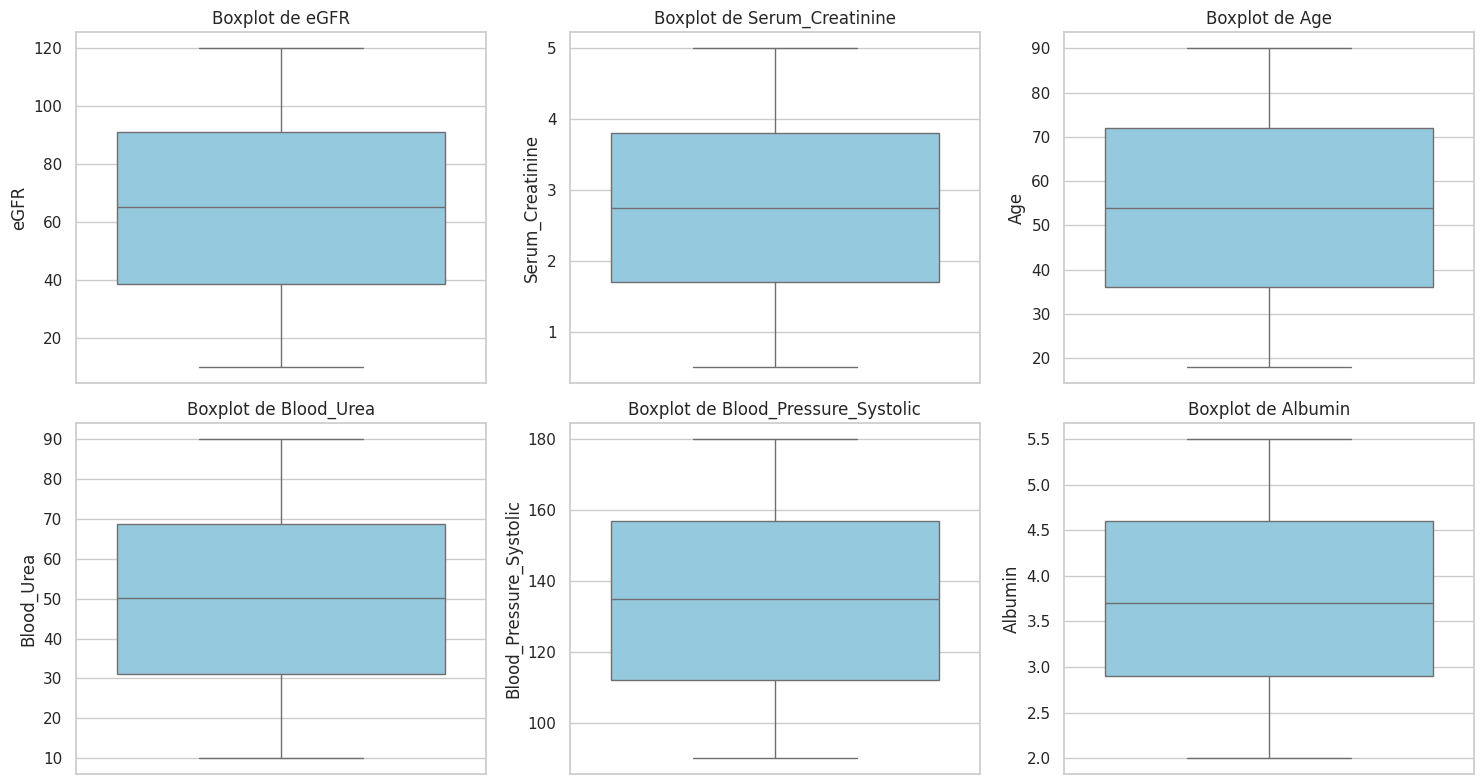

In [ ]:
columnas_numericas = df_General.select_dtypes(include=[np.number]).columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(columnas_numericas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df_General[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot de {col}')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

#### Verificar Outliers

In [ ]:
def contar_outliers_iqr(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    return ((serie < limite_inferior) | (serie > limite_superior)).sum()

outliers_resumen = {col: contar_outliers_iqr(df_General[col]) for col in columnas_numericas}
outliers_df = pd.DataFrame(list(outliers_resumen.items()), columns=['columna', 'n_outliers'])
outliers_df = outliers_df.sort_values('n_outliers', ascending=False)
display(outliers_df)

,columna,n_outliers
0,eGFR,0
1,Serum_Creatinine,0
2,Age,0
3,Blood_Urea,0
4,Blood_Pressure_Systolic,0
5,Albumin,0


Estrategia frente a valores atípicos. El conteo por rango intercuartílico (IQR) da cero atípicos en las seis variables numéricas seleccionadas. Esto no significa que los datos estén "limpios" en el sentido clínico: junto con el hecho de que las medias coinciden con las medianas y los histogramas tienen forma plana (no de campana), es evidencia de que las variables fueron generadas con distribuciones acotadas artificialmente, reforzando que el dataset es sintético. Por esa razón, y porque en un sistema de alarma temprana el paciente con un valor extremo es precisamente el que se busca detectar, se decidió no eliminar ni transformar ningún valor extremo.

#### Heatmaps

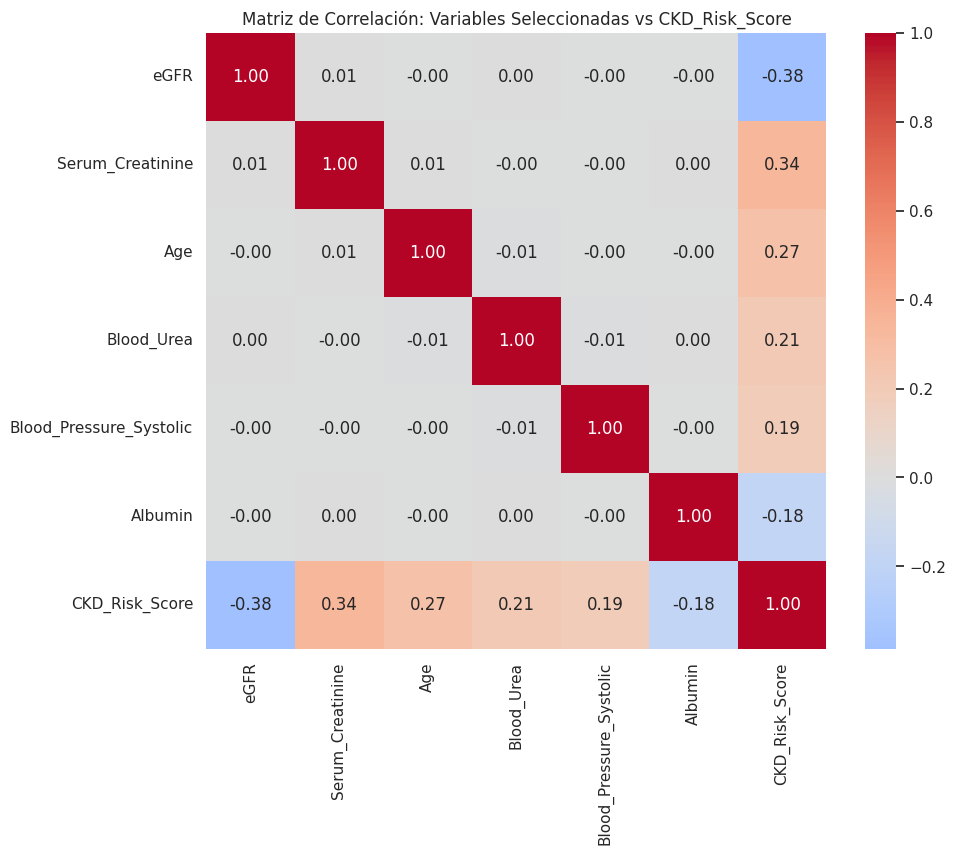

In [ ]:
# 1. Crear la lista con las numéricas seleccionadas + la variable objetivo
cols_matriz = list(top_numericas)
if 'CKD_Risk_Score' not in cols_matriz:
    cols_matriz.append('CKD_Risk_Score')

# 2. Generar el heatmap compacto
plt.figure(figsize=(10, 8))
corr = df[cols_matriz].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Matriz de Correlación: Variables Seleccionadas vs CKD_Risk_Score")
plt.show()

Interpretación de la matriz de correlación. Ninguna variable individual supera 0.4 de correlación con el score, lo que confirma que el riesgo no depende de un solo factor sino de la combinación de varios — el argumento central para justificar el uso de Machine Learning. Además, [Serum_Creatinine y eGFR / las variables que salgan correlacionadas entre sí en tu heatmap] muestran correlación entre ellas mismas, lo que indica que comparten información: es algo a tener en cuenta en la siguiente fase, porque dos predictoras muy correlacionadas entre sí no siempre aportan información nueva al modelo.

In [ ]:
df_modelo = df_General.copy()
binarias = ['Hypertension', 'Diabetes', 'Family_History_CKD']
mapa_binario = {'No': 0, 'Yes': 1}

for col in binarias:
    df_modelo[col] = df_modelo[col].map(mapa_binario)
mapa_fumador = {'Never': 0, 'Former': 1, 'Current': 2}
df_modelo['Smoking_Status'] = df_modelo['Smoking_Status'].map(mapa_fumador)


##Análisis de distribuciones y estadisticas

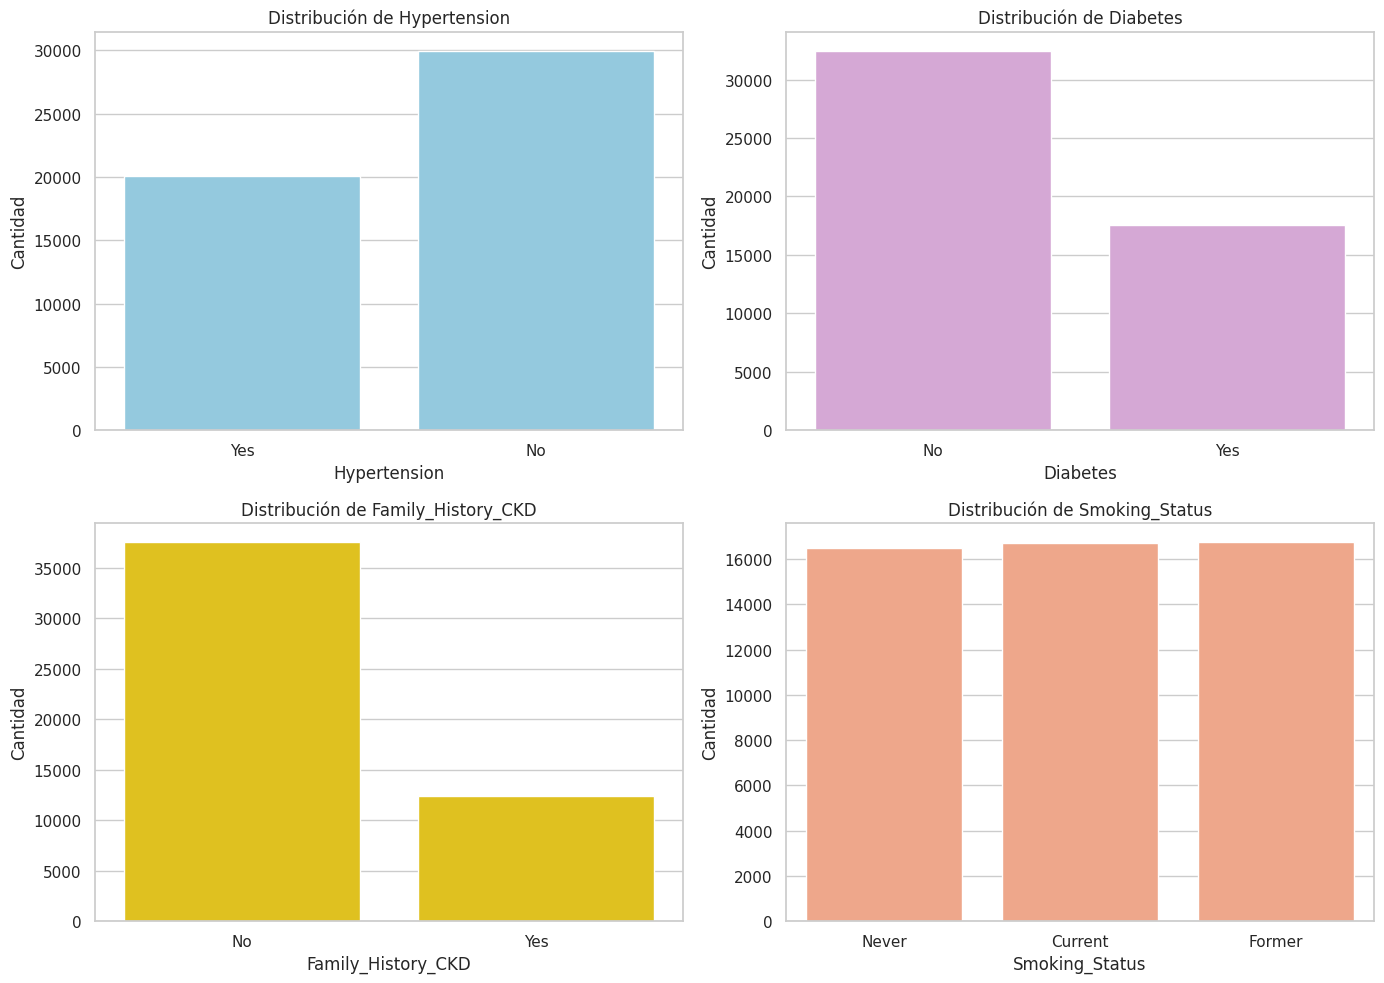

,Variable,Categoria,Frecuencia,Porcentaje
0,Hypertension,No,29964,59.93%
1,Hypertension,Yes,20036,40.07%
2,Diabetes,No,32471,64.94%
3,Diabetes,Yes,17529,35.06%
4,Family_History_CKD,No,37612,75.22%
5,Family_History_CKD,Yes,12388,24.78%
6,Smoking_Status,Former,16773,33.55%
7,Smoking_Status,Current,16726,33.45%
8,Smoking_Status,Never,16501,33.00%


In [ ]:
#1 Variables categoricas


plt.figure(figsize=(14, 10))

#Hypertension
plt.subplot(2, 2, 1)
sns.countplot(x='Hypertension', data=df_General, color='skyblue')
plt.title("Distribución de Hypertension")
plt.ylabel("Cantidad")

#Diabetes
plt.subplot(2, 2, 2)
sns.countplot(x='Diabetes', data=df_General, color='plum')
plt.title("Distribución de Diabetes")
plt.ylabel("Cantidad")

#Family_History_CKD
plt.subplot(2, 2, 3)
sns.countplot(x='Family_History_CKD', data=df_General, color='gold')
plt.title("Distribución de Family_History_CKD")
plt.ylabel("Cantidad")

#Smoking_Status
plt.subplot(2, 2, 4)
sns.countplot(x='Smoking_Status', data=df_General, color='lightsalmon')
plt.title("Distribución de Smoking_Status")
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

#Frecuencias y porcentajes de nuestras variables categoricas

variables = ['Hypertension', 'Diabetes', 'Family_History_CKD', 'Smoking_Status']
tablas = []

for col in variables:
    conteo = df_General[col].value_counts()
    porcentaje = df_General[col].value_counts(normalize=True) * 100

    tabla = pd.DataFrame({
        'Variable': col,
        'Categoria': conteo.index,
        'Frecuencia': conteo.values,
        'Porcentaje': porcentaje.values
    })

    tablas.append(tabla)

# Concatenar tablas de la lista
resumen = pd.concat(tablas, ignore_index=True)

display(resumen.style.format({'Porcentaje': '{:.2f}%'}))

##### Interpretación de las variables categóricas


*  **Hypertension**: El 59.93% de los pacientes no presenta hipertensión, mientras que el 40.07% si la presenta. A pesar de que la mayoria no tiene hipertensión, el grupo que si la tiene muestra un riesgo promedio considerablemente alto , confirma que es uno de los factores relevantes para el reisgo de ERC
*   **Diabetes**: El 64.94% de los pacientes no tiene diabetes, mientras que el 35.06% si la tiene.

* **Family_History_CKD:** El 75.22% de los pacientes no tiene antecedentes familiares de ERC, mientras que el 24.78% sí los tiene. Aunque es pequeño presenta la mayor diferencia de riesgo  entre todas las categóricas , sugiriendo un componente hereditario relevante en el riesgo de la enfermedad.
* **Smoking_Status**:16.773 pacientes (33.55%) son exfumadores, 16.726 (33.45%) fuman actualmente y 16.501 (33.00%) nunca han fumado. A diferencia de las demás variables categóricas, aquí no predomina un grupo sobre otro

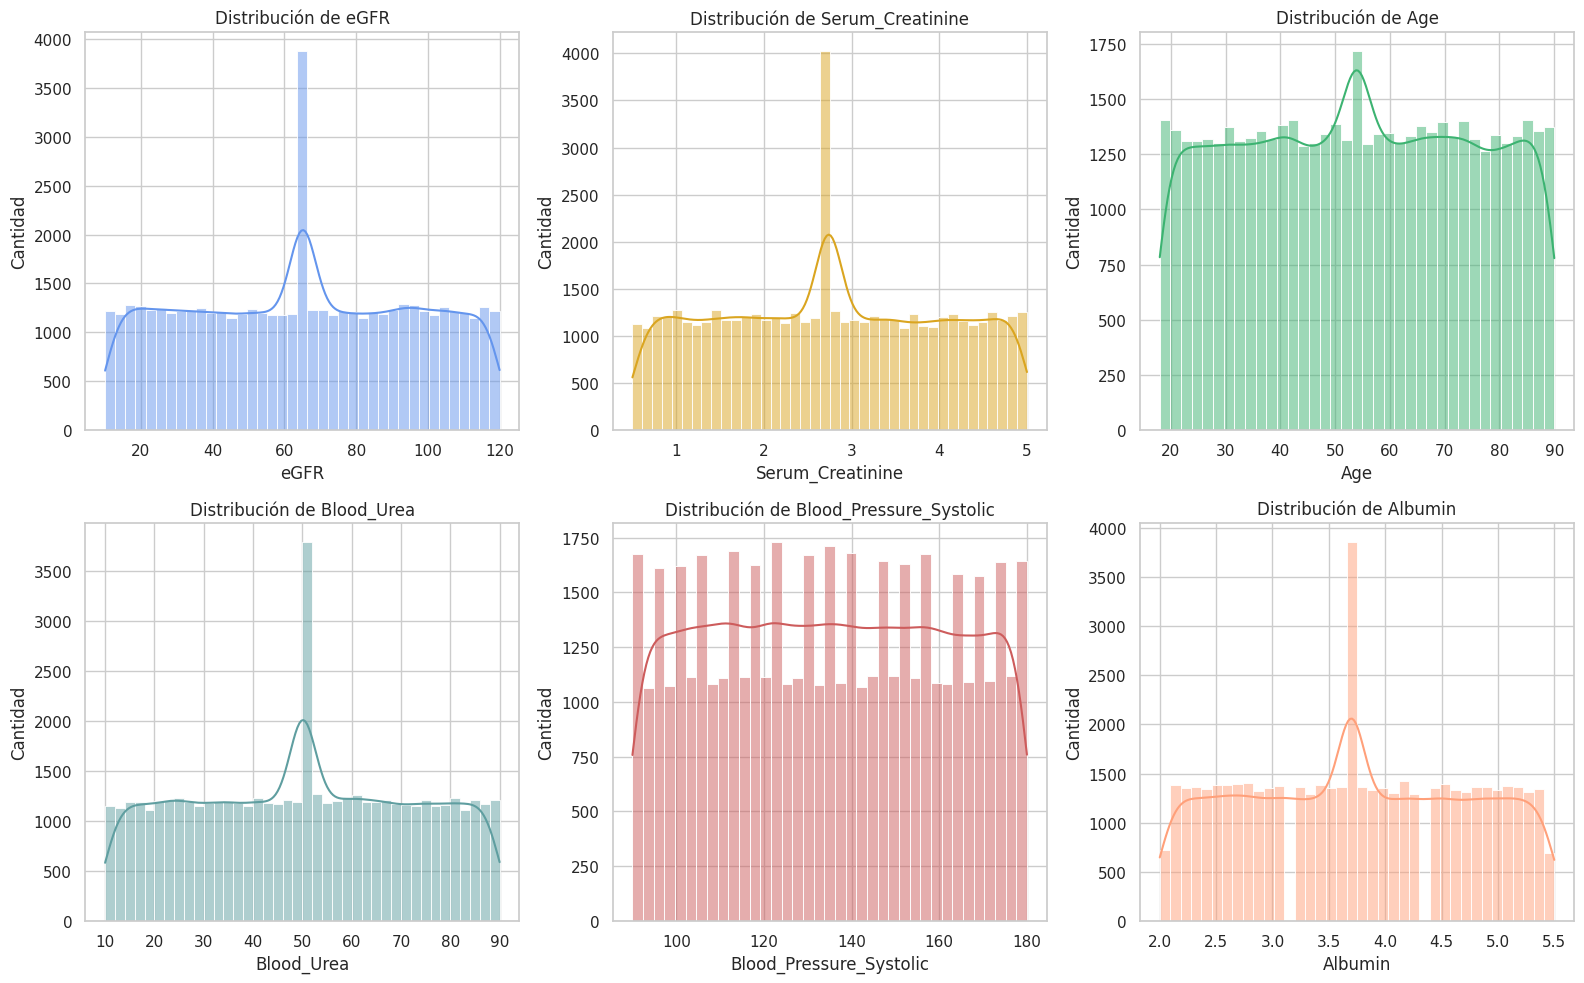

In [ ]:
#Variables Numericas

#2 Variables numericas

plt.figure(figsize=(16, 10))

#eGFR
plt.subplot(2, 3, 1)
sns.histplot(df_General['eGFR'], kde=True, color='cornflowerblue')
plt.title("Distribución de eGFR")
plt.ylabel("Cantidad")

#Serum_Creatinine
plt.subplot(2, 3, 2)
sns.histplot(df_General['Serum_Creatinine'], kde=True, color='goldenrod')
plt.title("Distribución de Serum_Creatinine")
plt.ylabel("Cantidad")

#Age
plt.subplot(2, 3, 3)
sns.histplot(df_General['Age'], kde=True, color='mediumseagreen')
plt.title("Distribución de Age")
plt.ylabel("Cantidad")

#Blood_Urea
plt.subplot(2, 3, 4)
sns.histplot(df_General['Blood_Urea'], kde=True, color='cadetblue')
plt.title("Distribución de Blood_Urea")
plt.ylabel("Cantidad")

#Blood_Pressure_Systolic
plt.subplot(2, 3, 5)
sns.histplot(df_General['Blood_Pressure_Systolic'], kde=True, color='indianred')
plt.title("Distribución de Blood_Pressure_Systolic")
plt.ylabel("Cantidad")

#Albumin
plt.subplot(2, 3, 6)
sns.histplot(df_General['Albumin'], kde=True, color='lightsalmon')
plt.title("Distribución de Albumin")
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

####Estadisticas

In [ ]:
#Estadisticas
variables_simetricas = ['eGFR', 'Serum_Creatinine', 'Age', 'Blood_Urea', 'Blood_Pressure_Systolic', 'Albumin']
tablas_sim = []

for col in variables_simetricas:
    media = df_General[col].mean()
    desv = df_General[col].std()

    tabla = pd.DataFrame({
        'Variable': [col],
        'Media': [media],
        'Desviación Estándar': [desv]
    })

    tablas_sim.append(tabla)

resumen_simetricas = pd.concat(tablas_sim, ignore_index=True)

display(resumen_simetricas.round(2))

,Variable,Media,Desviación Estándar
0,eGFR,64.96,31.00
1,Serum_Creatinine,2.75,1.26
2,Age,54.05,20.89
3,Blood_Urea,50.03,22.39
4,Blood_Pressure_Systolic,134.92,26.19
5,Albumin,3.74,0.99


###Comprobación de simetria

In [ ]:

resultados = []

umbral = 0.1

for col in top_numericas:

    media = df_General[col].mean()
    mediana = df_General[col].median()
    desv = df_General[col].std()

    diferencia = abs(media - mediana)
    indicador = diferencia / desv

    if indicador < umbral:
        forma = 'Simétrica'
    else:
        forma = 'Asimétrica'

    fila = {
        'Variable': col,
        'Media': round(media, 2),
        'Mediana': round(mediana, 2),
        'Desv': round(desv, 2),
        'Indicador': round(indicador, 4),
        'Forma': forma
    }
    resultados.append(fila)

tabla_simetria = pd.DataFrame(resultados)
display(tabla_simetria)

,Variable,Media,Mediana,Desv,Indicador,Forma
0,eGFR,64.96,65.10,31.00,0.0047,Simétrica
1,Serum_Creatinine,2.75,2.74,1.26,0.0083,Simétrica
2,Age,54.05,54.00,20.89,0.0022,Simétrica
3,Blood_Urea,50.03,50.10,22.39,0.0031,Simétrica
4,Blood_Pressure_Systolic,134.92,135.00,26.19,0.0030,Simétrica
5,Albumin,3.74,3.70,0.99,0.0407,Simétrica


### Cruce bivariado:

/tmp/ipykernel_450/4133190391.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='CKD_Risk', y=col, data=df, order=['Low','Moderate','High'],
/tmp/ipykernel_450/4133190391.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='CKD_Risk', y=col, data=df, order=['Low','Moderate','High'],
/tmp/ipykernel_450/4133190391.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='CKD_Risk', y=col, data=df, order=['Low','Moderate','High'],
/tmp/ipykernel_450/4133190391.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and

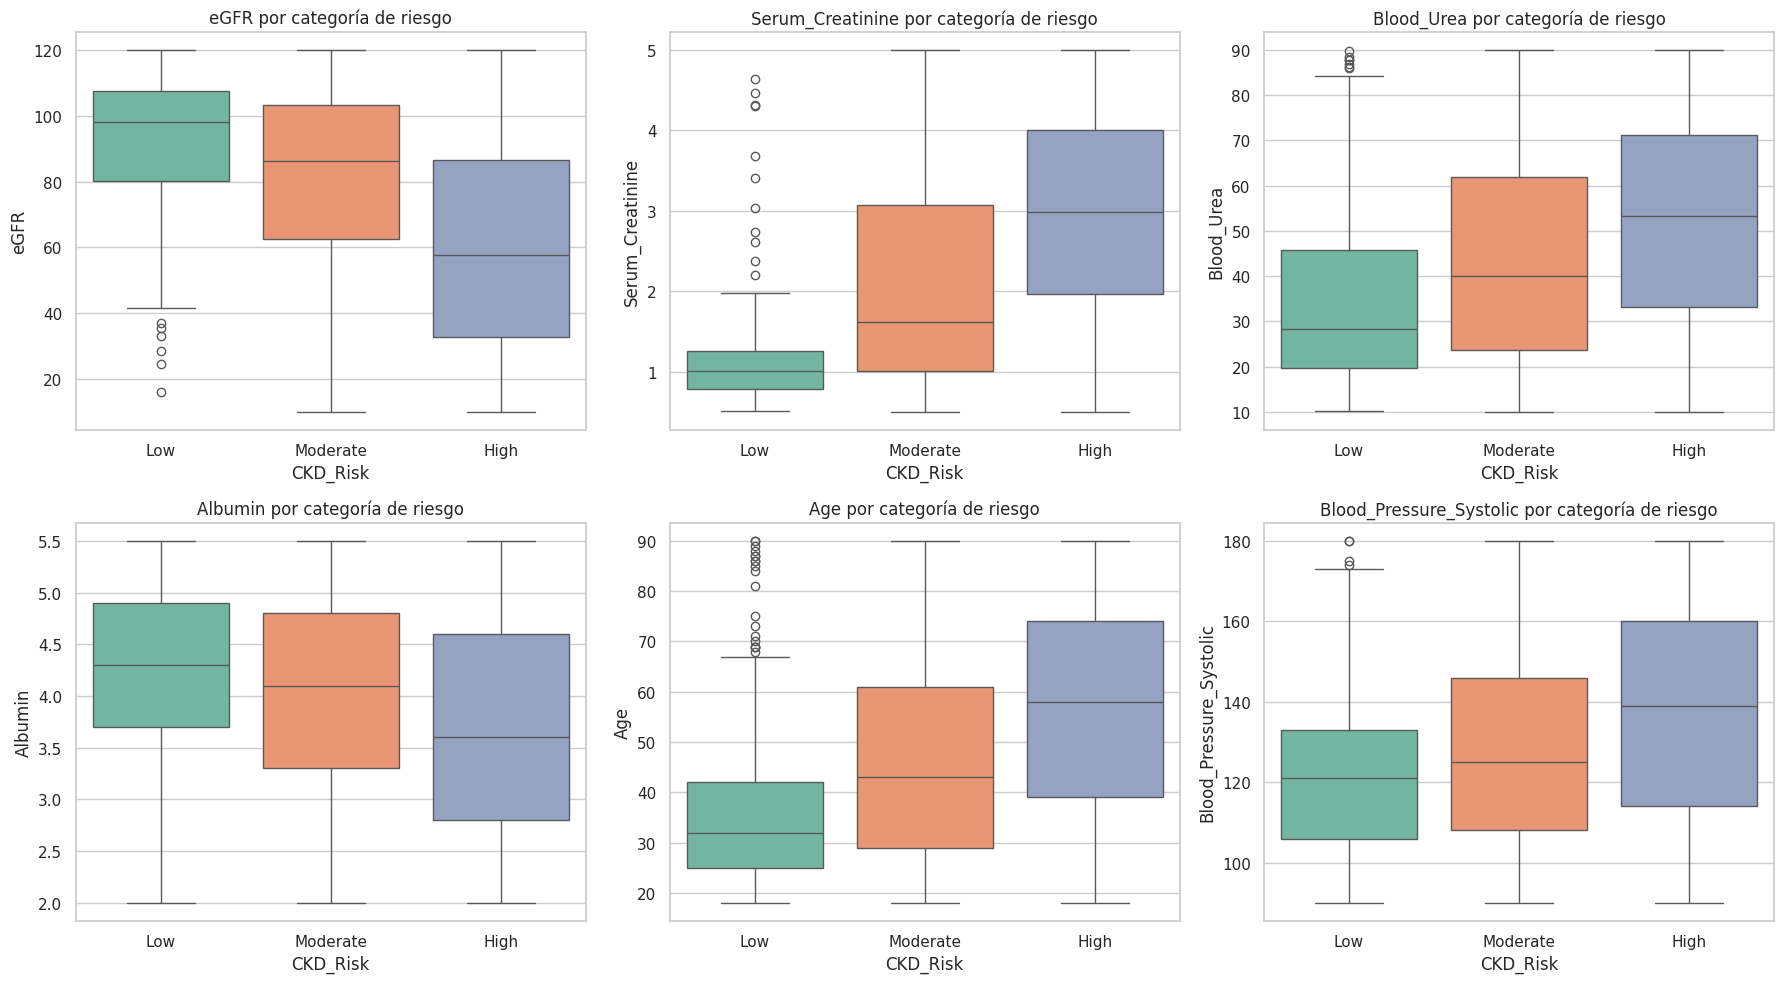

In [ ]:
top_vars = ['eGFR', 'Serum_Creatinine', 'Blood_Urea', 'Albumin', 'Age', 'Blood_Pressure_Systolic']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(top_vars):
    sns.boxplot(x='CKD_Risk', y=col, data=df, order=['Low','Moderate','High'],
                palette='Set2', ax=axes[i])
    axes[i].set_title(f'{col} por categoría de riesgo')

plt.tight_layout()
plt.show()

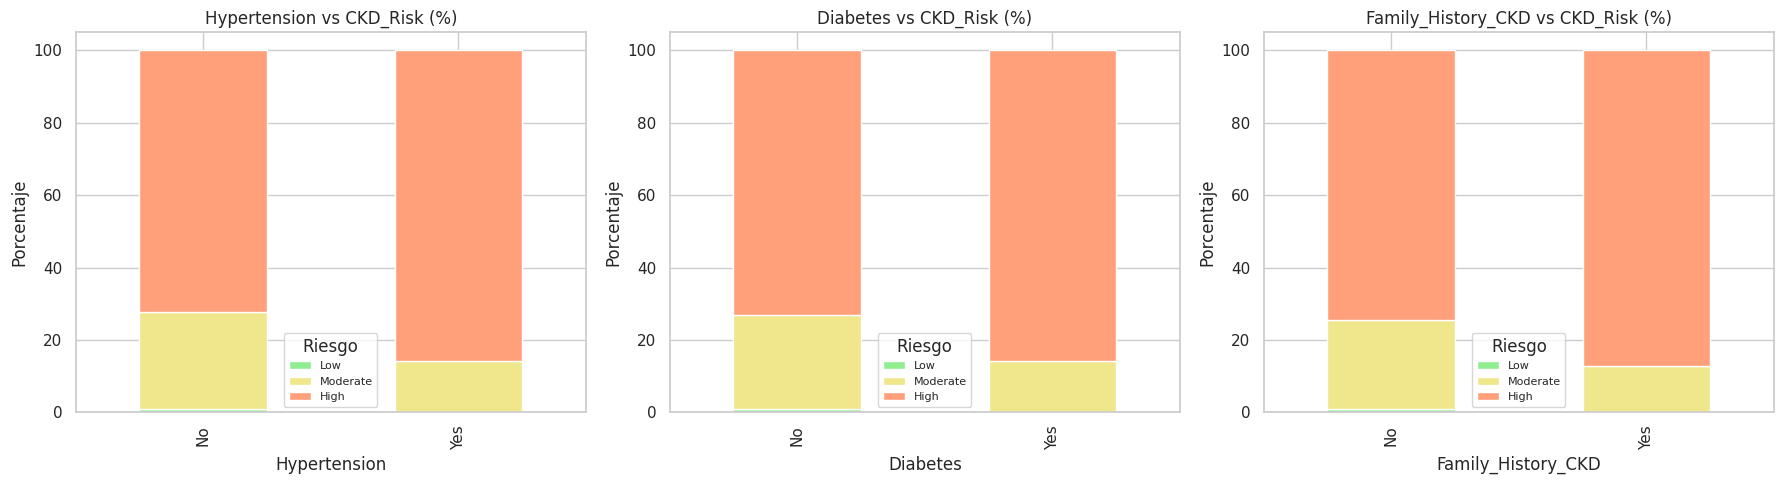

In [ ]:
cat_vars = ['Hypertension', 'Diabetes', 'Family_History_CKD']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_vars):
    tabla = pd.crosstab(df[col], df['CKD_Risk'], normalize='index') * 100
    tabla = tabla[['Low','Moderate','High']]
    tabla.plot(kind='bar', stacked=True, ax=axes[i], color=['lightgreen','khaki','lightsalmon'])
    axes[i].set_title(f'{col} vs CKD_Risk (%)')
    axes[i].set_ylabel('Porcentaje')
    axes[i].legend(title='Riesgo', fontsize=8)

plt.tight_layout()
plt.show()

#### Interpretacion de las variables
* **eGFR:** El valor promedio de la tasa de filtración glomerular estimada es de 64.95 ± 31.85 ml/min. La  desviación estándar indica una variabilidad  alta entre pacientes, es decir, es la mezcla de personas con una funcion renal normal y distintos grados de deterioro dentro del dataset.

* **Serum_creatine:** El promedio de creatinina en sangre es de 2.75±1.30 mg/dL, este valor esta por encima del rango normal de 0.7 a 1.3 mg/dL para hombres y 0.6 a 1.1 mg/dL en mujeres, por lo que se puede afirmar que este valor esta por encima del rango normal de referencia clinico, lo que sugiere que el dataset representa una población con una proporción importante de casos de riesgo renal avanzado.
* **Age:** la edad promedio de los pacientes es de 54.04±21.12 años, con alta dispersión, indica una población muy heterogénea en edad. El riesgo de ERC no aumenta linealmente, sino que se dispara a partir de los 60-65 años. Por eso el promedio general subestima el riesgo real del grupo de mayor edad.
* **Blood_Urea**: El promedio de urea en sangre es de 50.03 ± 23.01, se ubica en el limite superior del rango normal en adultos (10-50 mg/dL), y la alta desviación estándar indica que buena parte de los pacientes supera ese límite. La poblacion del dataset incluye un número alto de casos de reisgo renal elevado
* **Blood_Pressure_Systolic**: La presión arterial sistólica promedio es de 134.92±26.19 mmHg. Supera el rango considerado normal (menor a 120 mmHg), ubicándose en zona de hipertensión según los estándares clínicos habituales. Es coherente con la hipertensión como uno de los principales factores de riesgo asociados a la enfermedad renal crónica. El dataset representa una población con riesgo cardiovascular y renal elevado.
* **Albumin**: El valor promedio de albúmina en sangre es de 3.74 ± 1.01 g/dL. Este valor se ubica dentro del rango clínico normal de referencia (aproximadamente 3.5–5.0 g/dL), aunque la desviación estándar indica una variabilidad considerable entre pacientes,

## Conclusiones



  
1. Encontramos que las clases están muy desbalanceadas: hay muchas observaciones de una clase, menos de otra y muy pocas de la tercera. Esto parece deberse a cómo se definieron los rangos del score y no necesariamente a una realidad clínica.

2. Vimos que los valores extremos están bastante limitados. Esto nos hace pensar que los datos fueron generados artificialmente y representa una limitación importante, porque pueden no reflejar completamente los casos extremos que encontraríamos en datos clínicos reales.

## Pasos a seguir (Fase de Modelado Predictivo)
1. Dividir los datos en 80% para entrenamiento y 20% para prueba antes de realizar cualquier transformación. Luego, aplicar el escalamiento de variables numéricas y la imputación de datos faltantes, utilizando únicamente el conjunto de entrenamiento para evitar data leakage.

2. Entrenar y comparar dos modelos: Regresión Logística Multinomial como modelo base y Random Forest Classifier como modelo de ensamble. Se utilizará class_weight='balanced' para manejar el desbalance entre las clases. El desempeño se evaluará con F1-Score Macro y Recall por clase.

3. Crear un modelo de regresión que permita predecir el puntaje continuo de riesgo. Su precisión se evaluará mediante RMSE y R².
4. Analizar la importancia de cada variable en los modelos para identificar cuáles son los principales factores clínicos relacionados con el deterioro renal
5. Segmentación de Pacientes y Análisis de Subgrupos: Agrupar a los pacientes según sus características clínicas, utilizando técnicas de clustering o estratificación. Después, analizar si estos grupos ayudan a mejorar la capacidad predictiva y la generalización del modelo.

#Avance #2

## 0. Preparación de los datos

### 0.1 Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, ParameterGrid, ParameterSampler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,balanced_accuracy_score)

### 0.2 Construcción de X e y

- **`X`:** solo las variables seleccionadas en la fase 1. `CKD_Risk_Score` se excluye a propósito: es la puntuación que define el nivel de riesgo, así que incluirla le daría la respuesta al modelo.
- **Binarias:** `Hypertension`, `Diabetes` y `Family_History_CKD` pasan de `No`/`Yes` a `0`/`1`.
- **`y` (binaria):** `High` = 1 y `Low` + `Moderate` = 0. Así el problema es una alarma temprana: detectar a los pacientes de alto riesgo frente al resto.


In [ ]:
X = df[variables_seleccionadas].copy()
binarias = ['Hypertension', 'Diabetes', 'Family_History_CKD']
for col in binarias:
    X[col] = X[col].map({'No': 0, 'Yes': 1})

y = df['CKD_Risk'].map({'Low': 0, 'Moderate': 0, 'High': 1})
assert y.notna().all(), "Hay categorias de CKD_Risk sin mapear"

### División estratificada en entrenamiento, validación y prueba
Se divide el conjunto de datos en tres subconjuntos con proporciones 60 % entrenamiento, 20 % validación y 20 % prueba:

- **Primera partición:** se separa el 20 % para prueba (`X_test`, `y_test`), que se mantiene intacto hasta la evaluación final.
- **Segunda partición:** el 80 % restante se divide con `test_size=0.25`, lo que equivale al 20 % del total para validación y deja el 60 % para entrenamiento.
- Estratificación (`stratify`) mantiene la misma proporción de clases en los tres conjuntos. Es importante porque la clase Low es muy pequeña: sin estratificar, un conjunto podría quedar con muy pocos casos.
- Semilla (`random_state=42`)


In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)
print({'train': len(y_train), 'val': len(y_val), 'test': len(y_test)})
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'val': y_val.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(4))

{'train': 30000, 'val': 10000, 'test': 10000}
           train     val    test
CKD_Risk                        
1         0.7765  0.7764  0.7765
0         0.2235  0.2236  0.2235


### 0.4 Preprocesamiento con `ColumnTransformer`
Cada tipo de variable recibe su propio tratamiento:

- **Numéricas:** imputación con la **mediana** (robusta a valores extremos) y `StandardScaler` (media 0, desviación 1). El escalado importa sobre todo para SVM, que compara distancias.
- **Binarias (0/1):** imputación con la **moda**. Ya están codificadas, no necesitan más.
- **`Smoking_Status`:** imputación con la moda y `OneHotEncoder` (una columna por categoría). `handle_unknown='ignore'` evita errores si aparece una categoría nueva en validación o test.

`fit_transform` aprende medianas, medias y categorías **solo del entrenamiento**; validación y test usan `transform`. Así no se filtra información de esos conjuntos al modelo (*data leakage*).


In [ ]:
num_cols = [c for c in X.columns if c not in binarias + ['Smoking_Status']]
cat_cols = ['Smoking_Status']

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_cols),
    ('bin', SimpleImputer(strategy='most_frequent'), binarias),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

X_train_p = pre.fit_transform(X_train)
X_val_p = pre.transform(X_val)
X_test_p = pre.transform(X_test)
print(X_train_p.shape, X_val_p.shape, X_test_p.shape)

(30000, 12) (10000, 12) (10000, 12)


## 1. Clasificación binaria: Alto frente al resto
Se entrena un clasificador binario: **Alto** (1) frente a **Bajo + Moderado** (0). La métrica principal es el **recall de la clase Alto**: de los pacientes realmente de alto riesgo, cuántos detecta el modelo. En una alarma temprana, el error más costoso es no detectar a un paciente de alto riesgo (falso negativo).

###  Vista del dataset

In [ ]:
nombres = pre.get_feature_names_out()
df_train_p = pd.DataFrame(X_train_p, columns=nombres, index=X_train.index)
df_train_p.head()

,num__eGFR,num__Serum_Creatinine,num__Age,num__Blood_Urea,num__Blood_Pressure_Systolic,num__Albumin,bin__Hypertension,bin__Diabetes,bin__Family_History_CKD,cat__Smoking_Status_Current,cat__Smoking_Status_Former,cat__Smoking_Status_Never
3956,0.845478,1.255494,1.726900,-0.340167,-1.106803,0.565562,0.0,0.0,0.0,0.0,0.0,1.0
43431,1.522920,0.138625,-0.619288,-1.277527,-0.954071,0.869234,0.0,0.0,0.0,1.0,0.0,0.0
4129,0.042226,0.772310,1.631137,1.516697,1.069626,1.274129,1.0,1.0,0.0,0.0,0.0,1.0
14260,0.861608,-0.360402,0.003170,1.048017,-1.068620,1.172906,0.0,0.0,0.0,0.0,0.0,1.0
17610,-1.199750,-1.002008,-0.858695,-0.741893,-1.221352,-1.458917,0.0,1.0,0.0,0.0,0.0,1.0


### 1.1 Función de métricas
Clase positiva = Alto.

- **Accuracy:** aciertos totales. Es engañosa con clases desbalanceadas.
- **Precision:** de los que el modelo marca como Alto, cuántos lo son.
- **Recall:** de los que son Alto, cuántos detecta.
- **F1:** media armónica de precision y recall.
- **F1 macro:** promedio del F1 de ambas clases; penaliza ignorar la clase minoritaria.
- **TNR (recall de Bajo):** de los que son Bajo, cuántos se reconocen como Bajo.
- **Balanced accuracy:** promedio del recall de las dos clases.

In [ ]:
def metricas(y_real, pred):
    return {
        'accuracy':     accuracy_score(y_real, pred),
        'balanced_acc': balanced_accuracy_score(y_real, pred),
        'precision':    precision_score(y_real, pred, zero_division=0),
        'recall':       recall_score(y_real, pred),
        'f1':           f1_score(y_real, pred, zero_division=0),
        'f1_macro':     f1_score(y_real, pred, average='macro', zero_division=0),
        'tnr':          recall_score(y_real, pred, pos_label=0),

    }

### 1.2 Configuración de modelos y mallas de hiperparámetros

Cada modelo tiene una malla que se prueba **completa** (`ParameterGrid`, sin muestreo aleatorio).

- `class_weight='balanced'` en árbol, RF y SVM: penaliza más los errores en la clase minoritaria (Alto) sin cambiar los datos.
- GNB usa `priors=[0.5, 0.5]`: fija la probabilidad previa de cada clase en 50/50, para que no aprenda la proporción del conjunto.

In [ ]:
config = {
    'gnb':   (GaussianNB, {'priors': [0.5, 0.5]},
              {'var_smoothing': [1e-9, 1e-5, 1e-3, 1e-1]},
              None),
    'arbol': (DecisionTreeClassifier, {'random_state': 42, 'class_weight': 'balanced'},
              {'max_depth': [3, 5, 8, 12, None],
               'min_samples_leaf': [1, 5, 10, 25, 50],
               'criterion': ['gini', 'entropy']},
              None),
    'rf':    (RandomForestClassifier, {'random_state': 42, 'n_jobs': -1, 'class_weight': 'balanced'},
              {'n_estimators': [100, 200],
               'max_depth': [6, 8, 12],
               'min_samples_leaf': [1, 5, 10, 20, 50],
               'max_features': ['sqrt', 0.5]},
              15),
    'svm':   (SVC, {'random_state': 42, 'class_weight': 'balanced'},
              {'C': [1, 5, 10, 50],
               'kernel': ['rbf'],
               'gamma': ['scale', 0.1, 0.3, 1]},
              None),
}

### 1.3 Búsqueda de hiperparámetros

Cada combinación de la malla se entrena una vez sobre el conjunto de entrenamiento y se guardan sus métricas de validación y de entrenamiento. Se conserva el mejor modelo de cada tipo con criterio **recall** en validación y desempate por **F1**. Las predicciones de test se guardan para el reporte final, pero no influyen en la elección del modelo.

In [ ]:


CRITERIO = 'recall'

filas = []
mejores = {}
pred = {}

for nombre, (Modelo, fijos, grid, n_iter) in config.items():
    combos = (
        list(ParameterGrid(grid))
        if n_iter is None
        else list(ParameterSampler(grid, n_iter=n_iter, random_state=42))
    )

    for i, params in enumerate(combos):
        id_ = f"{nombre}_{i}"
        modelo = Modelo(**fijos, **params).fit(X_train_p, y_train)

        p_train = modelo.predict(X_train_p)
        p_val = modelo.predict(X_val_p)

        pred[id_] = {
            'val': p_val,
            'test': modelo.predict(X_test_p)
        }

        m_val = metricas(y_val, p_val)
        m_train = {f"{k}_train": v for k, v in metricas(y_train, p_train).items()}

        fila = {'id': id_, 'modelo': nombre, 'params': params, **m_val, **m_train}
        filas.append(fila)

        score = (fila[CRITERIO], fila['f1'])
        if nombre not in mejores or score > (mejores[nombre]['fila'][CRITERIO], mejores[nombre]['fila']['f1']):
            mejores[nombre] = {'fila': fila, 'modelo': modelo}

res = pd.DataFrame(filas)
ranking = res.sort_values([CRITERIO, 'f1'], ascending=False)
mejor = ranking.groupby('modelo', as_index=False).first()
columnas_visibles = ['id', 'modelo', 'accuracy', 'precision', 'recall', 'f1', 'f1_train']
print(res[columnas_visibles].round(3).to_string(index=False))

      id modelo  accuracy  precision  recall    f1  f1_train
   gnb_0    gnb     0.784      0.937   0.774 0.848     0.846
   gnb_1    gnb     0.784      0.937   0.774 0.848     0.846
   gnb_2    gnb     0.784      0.937   0.773 0.847     0.846
   gnb_3    gnb     0.770      0.952   0.741 0.834     0.833
 arbol_0  arbol     0.746      0.896   0.762 0.824     0.818
 arbol_1  arbol     0.746      0.896   0.762 0.824     0.818
 arbol_2  arbol     0.746      0.896   0.762 0.824     0.818
 arbol_3  arbol     0.746      0.896   0.762 0.824     0.818
 arbol_4  arbol     0.746      0.896   0.762 0.824     0.818
 arbol_5  arbol     0.730      0.919   0.714 0.804     0.809
 arbol_6  arbol     0.730      0.919   0.714 0.804     0.809
 arbol_7  arbol     0.730      0.919   0.714 0.804     0.809
 arbol_8  arbol     0.730      0.919   0.714 0.804     0.809
 arbol_9  arbol     0.730      0.919   0.714 0.804     0.809
arbol_10  arbol     0.771      0.928   0.765 0.838     0.853
arbol_11  arbol     0.77

### 1.4 Diagnóstico de sobreajuste: entrenamiento frente a validación

Compara el desempeño en entrenamiento con el de validación. Si el desempeño en entrenamiento es mucho mayor, el modelo memoriza los datos y generaliza peor. La columna *brecha recall* es la diferencia entre ambos.

In [ ]:
tabla = mejor[['recall_train', 'recall', 'precision_train', 'precision', 'f1_train', 'f1']].copy()
tabla['brecha recall'] = tabla['recall_train'] - tabla['recall']
display(tabla.round(3))

,recall_train,recall,precision_train,precision,f1_train,f1,brecha recall
0,0.998,0.875,1.000,0.867,0.999,0.871,0.124
1,0.773,0.774,0.934,0.937,0.846,0.848,-0.001
2,0.932,0.883,0.986,0.914,0.958,0.898,0.049
3,0.987,0.878,0.999,0.875,0.993,0.877,0.108


### 1.5 Mejor configuración por modelo

Para cada modelo se muestra la combinación de hiperparámetros con mejor criterio en validación.

In [ ]:
res_full = pd.concat([res.drop(columns='params'),
                      pd.json_normalize(res['params'])], axis=1)

cols_ver = ['recall', 'precision', 'f1', 'var_smoothing',
            'max_depth', 'min_samples_leaf', 'criterion',
            'n_estimators', 'max_features',
            'C', 'gamma', 'kernel']
cols_ver = [c for c in cols_ver if c in res_full.columns]

display(res_full.sort_values([CRITERIO, 'f1'], ascending=False)
        .groupby('modelo').head(1).set_index('modelo')[cols_ver].round(3))

,recall,precision,f1,var_smoothing,max_depth,min_samples_leaf,criterion,n_estimators,max_features,C,gamma,kernel
modelo,,,,,,,,,,,,
rf,0.883,0.914,0.898,NaN,12.0,1.0,NaN,100.0,0.5,NaN,NaN,NaN
svm,0.878,0.875,0.877,NaN,NaN,NaN,NaN,NaN,NaN,10.0,1,rbf
arbol,0.875,0.867,0.871,NaN,NaN,1.0,gini,NaN,NaN,NaN,NaN,NaN
gnb,0.774,0.937,0.848,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.6 Top 5 por modelo y los dos mejores

Se muestran las cinco mejores combinaciones de cada modelo, para ver si el mejor resultado es un caso aislado. Luego, los dos modelos con mejor criterio, que pasan al test final.

In [ ]:
metr = ['accuracy', 'precision', 'recall', 'f1']

print('TOP 5 POR MODELO (criterio único)')
for nombre, g in ranking.groupby('modelo'):
    print(nombre)
    display(g.head(5)[metr].round(3))

print('MEJOR MODELO POR CRITERIO')
dos_mejores = ranking.groupby('modelo').head(1).head(2)
display(dos_mejores[['modelo'] + metr].round(3))
for i, fila in dos_mejores.iterrows():
    print(i, fila['modelo'], fila['params'])

TOP 5 POR MODELO (criterio único)
arbol


,accuracy,precision,recall,f1
24,0.799,0.867,0.875,0.871
49,0.800,0.874,0.868,0.871
50,0.784,0.894,0.819,0.855
25,0.783,0.897,0.814,0.854
19,0.783,0.908,0.802,0.852


gnb


,accuracy,precision,recall,f1
0,0.784,0.937,0.774,0.848
1,0.784,0.937,0.774,0.848
2,0.784,0.937,0.773,0.847
3,0.770,0.952,0.741,0.834


rf


,accuracy,precision,recall,f1
65,0.845,0.914,0.883,0.898
68,0.841,0.924,0.867,0.894
59,0.834,0.928,0.852,0.888
57,0.837,0.934,0.850,0.890
63,0.829,0.936,0.837,0.884


svm


,accuracy,precision,recall,f1
80,0.808,0.875,0.878,0.877
84,0.806,0.873,0.878,0.875
76,0.810,0.880,0.874,0.877
72,0.814,0.914,0.840,0.876
83,0.792,0.898,0.825,0.860


MEJOR MODELO POR CRITERIO


,modelo,accuracy,precision,recall,f1
65,rf,0.845,0.914,0.883,0.898
80,svm,0.808,0.875,0.878,0.877


65 rf {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 12}
80 svm {'C': 10, 'gamma': 1, 'kernel': 'rbf'}


### 1.7 Validación: matrices de confusión y métricas

Compara los modelos en validación con los hiperparámetros ya elegidos. Esta sección no entrena modelos nuevos.

In [ ]:
sns.set_theme(style='whitegrid')
PAL = sns.color_palette('Set2')

NOMBRES = {'gnb': 'GNB', 'arbol': 'DecisionTree', 'rf': 'RandomForest', 'svm': 'SVM'}
REF = 'RandomForest'
FRACS = [0.2, 0.4, 0.6, 0.8, 1.0]

clases = np.sort(np.unique(y_train))
binario = len(clases) == 2
POS = clases.max()
AVG = 'binary' if binario else 'macro'
NOM_CLASES = ['Bajo', 'Alto'] if binario else ['Bajo', 'Medio', 'Alto']


In [ ]:
def met(y, p, avg=None):
    avg = avg or AVG
    kw = dict(pos_label=POS) if avg == 'binary' else {}
    return {'Accuracy': accuracy_score(y, p),
            'Precision': precision_score(y, p, average=avg, zero_division=0, **kw),
            'Recall': recall_score(y, p, average=avg, zero_division=0, **kw),
            'F1': f1_score(y, p, average=avg, zero_division=0, **kw)}


def nuevo_modelo(clave):
    """Mismos parámetros que el mejor de la búsqueda (criterio único)."""
    Modelo, fijos, _, _ = config[clave]
    return Modelo(**fijos, **mejores[clave]['fila']['params'])

orden = [NOMBRES[c] for c in config]


In [ ]:
modelos = {NOMBRES[c]: mejores[c]['modelo'] for c in config}
pred_val = {NOMBRES[c]: pred[mejores[c]['fila']['id']]['val'] for c in config}


def matriz_confusion(ax, y, p, titulo):
    cm = confusion_matrix(y, p, labels=clases)
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    txt = np.array([[f'{cm[i, j]}\n({pct[i, j]:.1f}%)' for j in range(len(clases))]
                    for i in range(len(clases))])
    sns.heatmap(cm, annot=txt, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=NOM_CLASES, yticklabels=NOM_CLASES)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')


**Matriz de confusión:** las filas son la clase real y las columnas la clase predicha. Cada celda muestra el número de casos y el porcentaje de su fila. La diagonal son los aciertos.

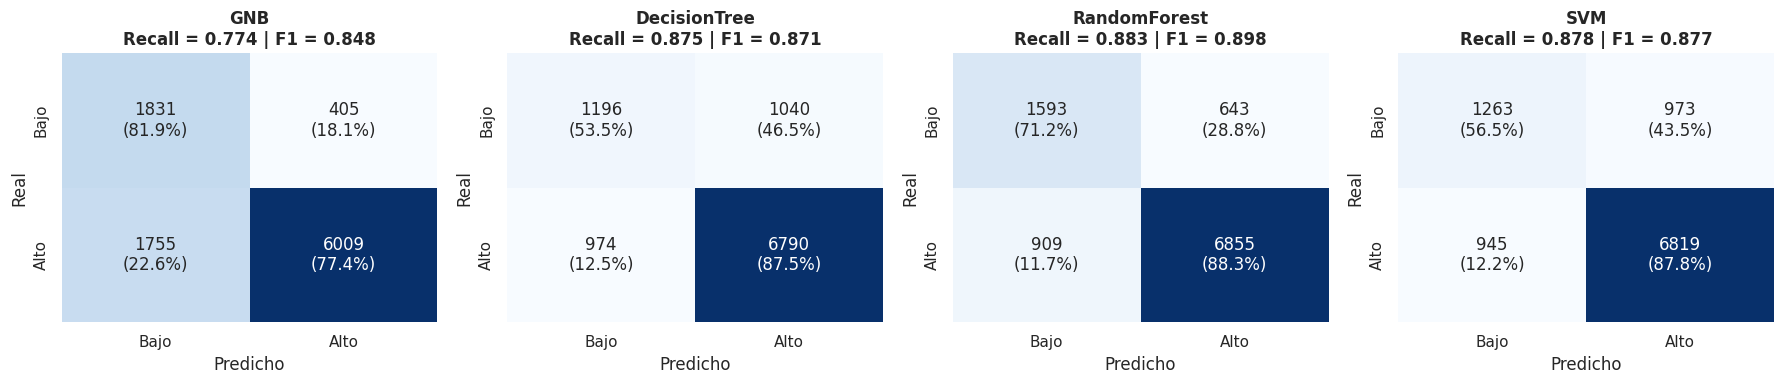

In [ ]:
fig, axes = plt.subplots(1, len(orden), figsize=(4.5 * len(orden), 4))
for ax, n in zip(axes, orden):
    m = met(y_val, pred_val[n])
    matriz_confusion(ax, y_val, pred_val[n], f"{n}\nRecall = {m['Recall']:.3f} | F1 = {m['F1']:.3f}")
plt.tight_layout(); plt.show()

Barras con las cuatro métricas de cada modelo en validación.

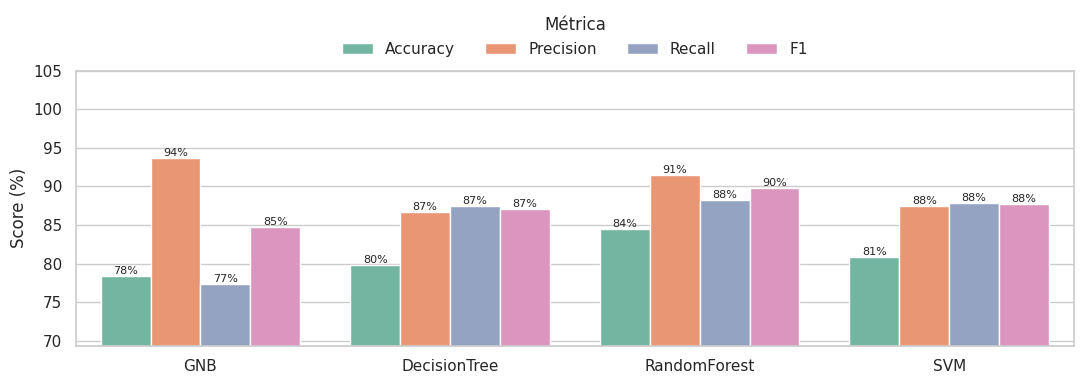

In [ ]:
tab = pd.DataFrame({n: met(y_val, pred_val[n]) for n in orden}).T * 100
tab_l = tab.reset_index().melt(id_vars='index', var_name='Métrica', value_name='Score')
plt.figure(figsize=(11, 4))
ax = sns.barplot(data=tab_l, x='index', y='Score', hue='Métrica', palette='Set2', order=orden)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', fontsize=8)
plt.ylim(max(0, tab.values.min() - 8), 105)
plt.xlabel(''); plt.ylabel('Score (%)')
plt.legend(title='Métrica', ncol=4, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.show()

### 1.8 Curvas de aprendizaje

Se reentrena cada mejor modelo con 20 %, 40 %, 60 % y 80 % del entrenamiento (muestreo estratificado) y se evalúa en validación. El 100 % corresponde al modelo ya entrenado en la búsqueda. Si la curva sigue subiendo al agregar datos, más datos ayudarían; si se aplana, el límite no es la cantidad de datos. La gráfica muestra el F1 en validación.

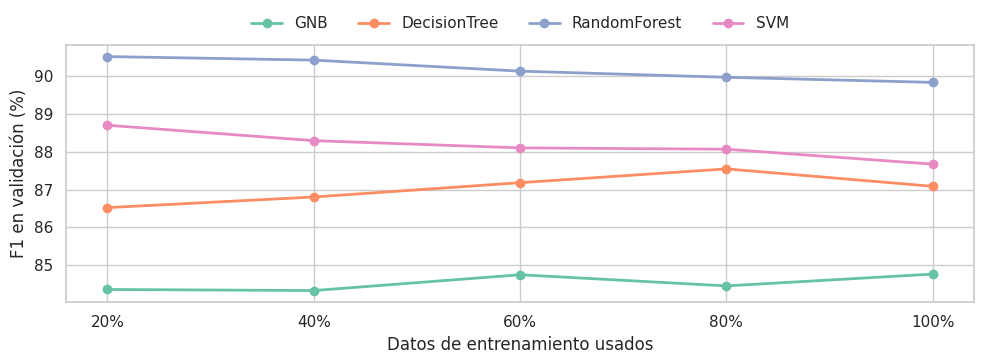

In [ ]:
filas = []
for f in FRACS:
    if f < 1:
        Xs, _, ys, _ = train_test_split(X_train_p, y_train, train_size=f,
                                        stratify=y_train, random_state=42)
    else:
        Xs, ys = X_train_p, y_train
    for clave in config:
        n = NOMBRES[clave]
        if f == 1.0:
            p = pred_val[n]
        else:
            p = nuevo_modelo(clave).fit(Xs, ys).predict(X_val_p)
        filas.append({'modelo': n, 'frac': f, **met(y_val, p)})
lc = pd.DataFrame(filas)
lc['pct'] = (lc['frac'] * 100).astype(int).astype(str) + '%'

plt.figure(figsize=(10, 3.8))
for i, n in enumerate(orden):
    d = lc[lc.modelo == n]
    plt.plot(d['pct'], d['F1'] * 100, marker='o', lw=2, color=PAL[i], label=n)
plt.xlabel('Datos de entrenamiento usados'); plt.ylabel('F1 en validación (%)')
plt.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.show()

### 1.9 Diferencia de cada modelo respecto a RandomForest

Valores por encima de 0 indican que el modelo supera a RandomForest con ese tamaño de entrenamiento. Se muestran F1, precisión y recall.

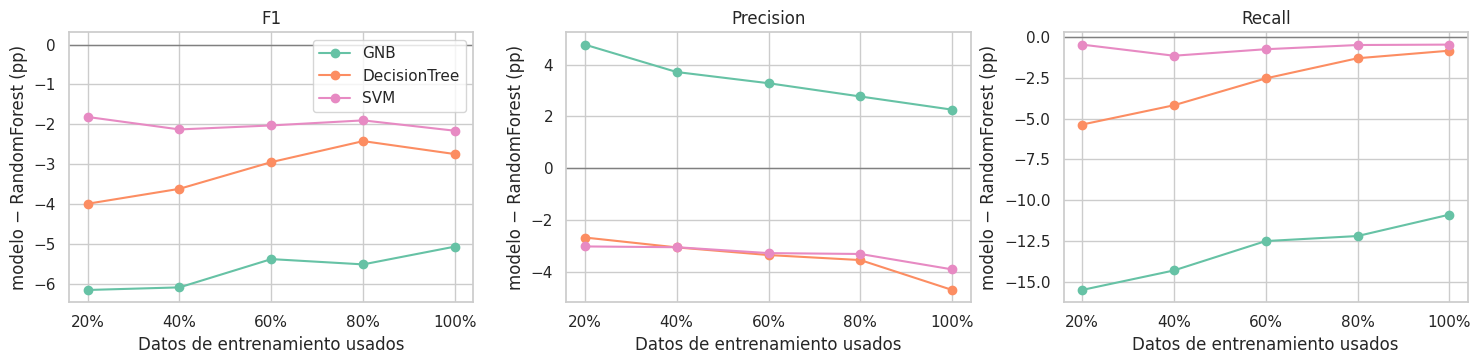

In [ ]:
otros = [n for n in orden if n != REF]
ref = lc[lc.modelo == REF].set_index('frac')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, m in zip(axes, ['F1', 'Precision', 'Recall']):
    for n in otros:
        d = lc[lc.modelo == n].set_index('frac')
        ax.plot(d['pct'], (d[m] - ref[m]) * 100, marker='o', color=PAL[orden.index(n)], label=n)
    ax.axhline(0, color='gray', lw=1)
    ax.set_title(m); ax.set_xlabel('Datos de entrenamiento usados')
    ax.set_ylabel(f'modelo − {REF} (pp)')
axes[0].legend()
plt.tight_layout(); plt.show()

La misma comparación en barras horizontales, con el valor exacto de cada diferencia.

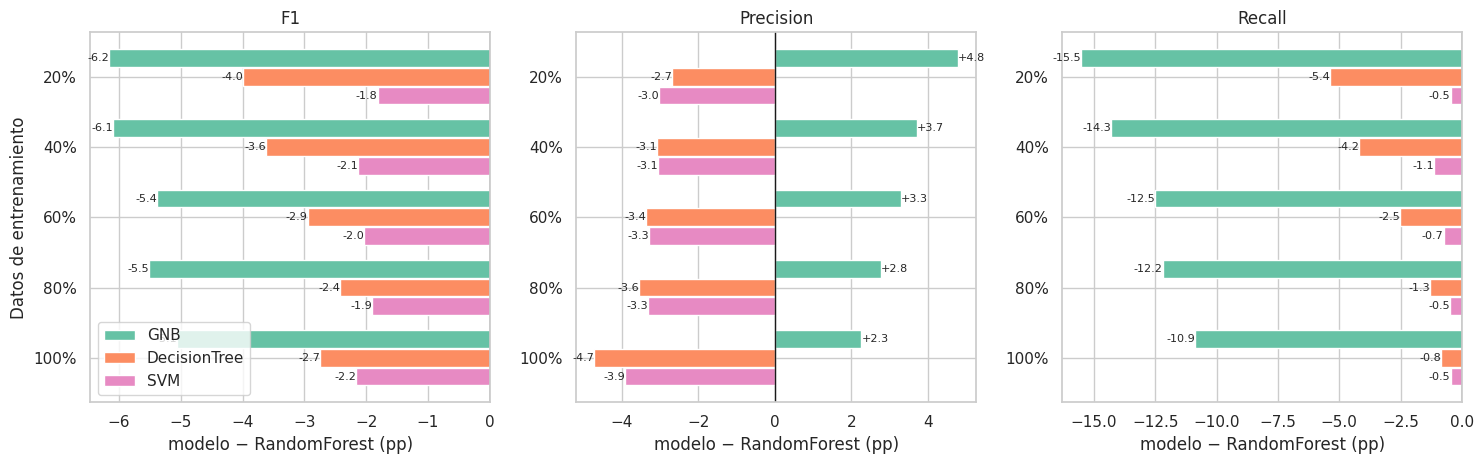

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
alto = 0.8 / len(otros)
for ax, m in zip(axes, ['F1', 'Precision', 'Recall']):
    for j, n in enumerate(otros):
        d = lc[lc.modelo == n].set_index('frac')
        v = ((d[m] - ref[m]) * 100).values
        y = np.arange(len(FRACS)) + (j - (len(otros) - 1) / 2) * alto
        ax.barh(y, v, height=alto * 0.95, color=PAL[orden.index(n)], label=n)
        for yy, vv in zip(y, v):
            ax.text(vv, yy, f'{vv:+.1f}', va='center',
                    ha='right' if vv < 0 else 'left', fontsize=8)
    ax.set_yticks(range(len(FRACS))); ax.set_yticklabels([f'{int(f * 100)}%' for f in FRACS])
    ax.invert_yaxis(); ax.axvline(0, color='k', lw=1)
    ax.set_title(m); ax.set_xlabel(f'modelo − {REF} (pp)')
axes[0].set_ylabel('Datos de entrenamiento')
axes[0].legend(loc='lower left')
plt.tight_layout(); plt.show()

### 1.10 Errores de validación respecto a RandomForest

Para cada modelo: errores de RandomForest que corrige (verde) y errores nuevos que introduce (rojo). **Inicial** son los errores totales de RandomForest; **Final** son los errores totales del otro modelo, no los que quedan después de corregir. La gráfica de la derecha muestra el desempeño de RandomForest con más datos.

### 1.11 Test final de los dos mejores modelos

Los dos modelos con mejor criterio en validación se evalúan una sola vez en el conjunto de test. Se reportan accuracy, precisión, recall, F1 y TNR de la clase Alto, el F1 por clase y las matrices de confusión.

In [ ]:
def clave_mejor(fila):
    return (fila[CRITERIO], fila['f1'])

,accuracy,precision,recall,f1,tnr
RandomForest,0.846,0.912,0.887,0.899,0.703
SVM,0.820,0.879,0.891,0.885,0.573


Recall = Alto detectado (criterio) · TNR = Bajo detectado


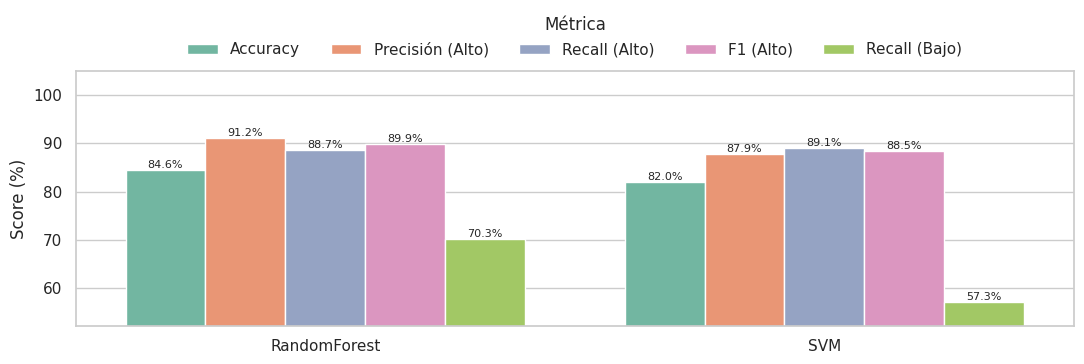

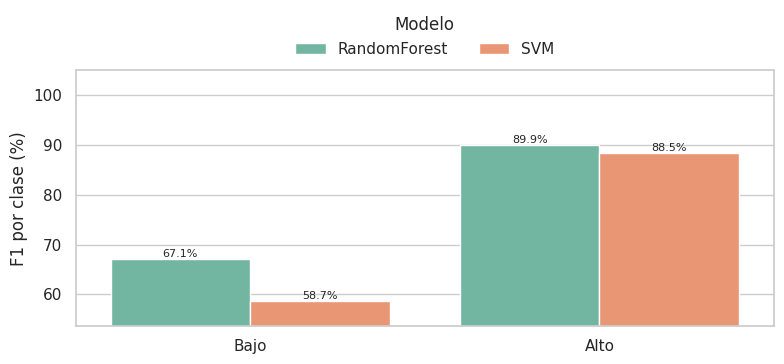

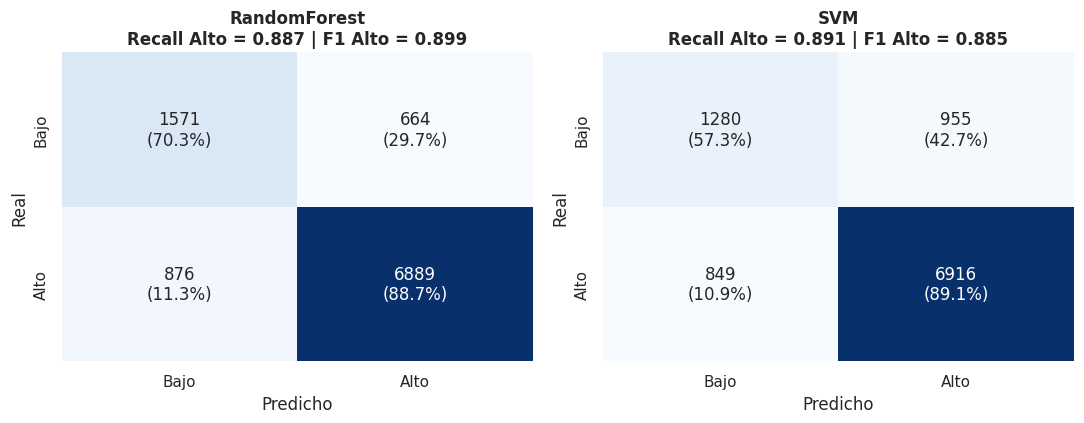

In [ ]:
ordenados = sorted(config, key=lambda c: clave_mejor(mejores[c]['fila']), reverse=True)[:2]
finalistas = [NOMBRES[c] for c in ordenados]
pred_te = {NOMBRES[c]: pred[mejores[c]['fila']['id']]['test'] for c in ordenados}

# 1. Tabla y barras: métricas binarias de la clase Alto y de la clase Bajo (TNR)
tabla_test = pd.DataFrame({n: metricas(y_test, p) for n, p in pred_te.items()}).T
tabla_test = tabla_test[['accuracy', 'precision', 'recall', 'f1', 'tnr']]
display(tabla_test.round(3))
print('Recall = Alto detectado (criterio) · TNR = Bajo detectado')

t8 = (tabla_test.rename_axis('modelo').reset_index()
      .rename(columns={'accuracy': 'Accuracy', 'precision': 'Precisión (Alto)',
                       'recall': 'Recall (Alto)', 'f1': 'F1 (Alto)', 'tnr': 'Recall (Bajo)'})
      .melt(id_vars='modelo', var_name='Métrica', value_name='Score'))
t8['Score'] *= 100

plt.figure(figsize=(11, 3.8))
ax = sns.barplot(data=t8, x='modelo', y='Score', hue='Métrica', palette='Set2')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', fontsize=8)
plt.ylim(max(0, t8['Score'].min() - 5), 105); plt.xlabel(''); plt.ylabel('Score (%)')
plt.legend(title='Métrica', ncol=5, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.show()

# 2. F1 por clase Bajo y Alto
f1c = pd.DataFrame({n: f1_score(y_test, p, average=None, labels=[0, 1]) * 100
                    for n, p in pred_te.items()}, index=['Bajo', 'Alto'])
f1c = f1c.reset_index().melt(id_vars='index', var_name='Modelo', value_name='F1')
plt.figure(figsize=(8, 3.8))
ax = sns.barplot(data=f1c, x='index', y='F1', hue='Modelo', palette='Set2')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', fontsize=8)
plt.ylim(max(0, f1c['F1'].min() - 5), 105); plt.xlabel(''); plt.ylabel('F1 por clase (%)')
plt.legend(title='Modelo', ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.show()

# 3. Matrices de confusión en test
fig, axes = plt.subplots(1, len(finalistas), figsize=(5.5 * len(finalistas), 4.4))
axes = np.atleast_1d(axes)
for ax, n in zip(axes, finalistas):
    f = tabla_test.loc[n]
    matriz_confusion(ax, y_test, pred_te[n],
                     f"{n}\nRecall Alto = {f['recall']:.3f} | F1 Alto = {f['f1']:.3f}")
plt.tight_layout(); plt.show()

### 1.12 Curvas de hiperparámetros: entrenamiento frente a validación

Para cada hiperparámetro, por cada valor probado se toma la mejor combinación que lo usa, sin reentrenar. La línea de entrenamiento y la de validación muestran dónde se separan (sobreajuste). La estrella marca el valor elegido.

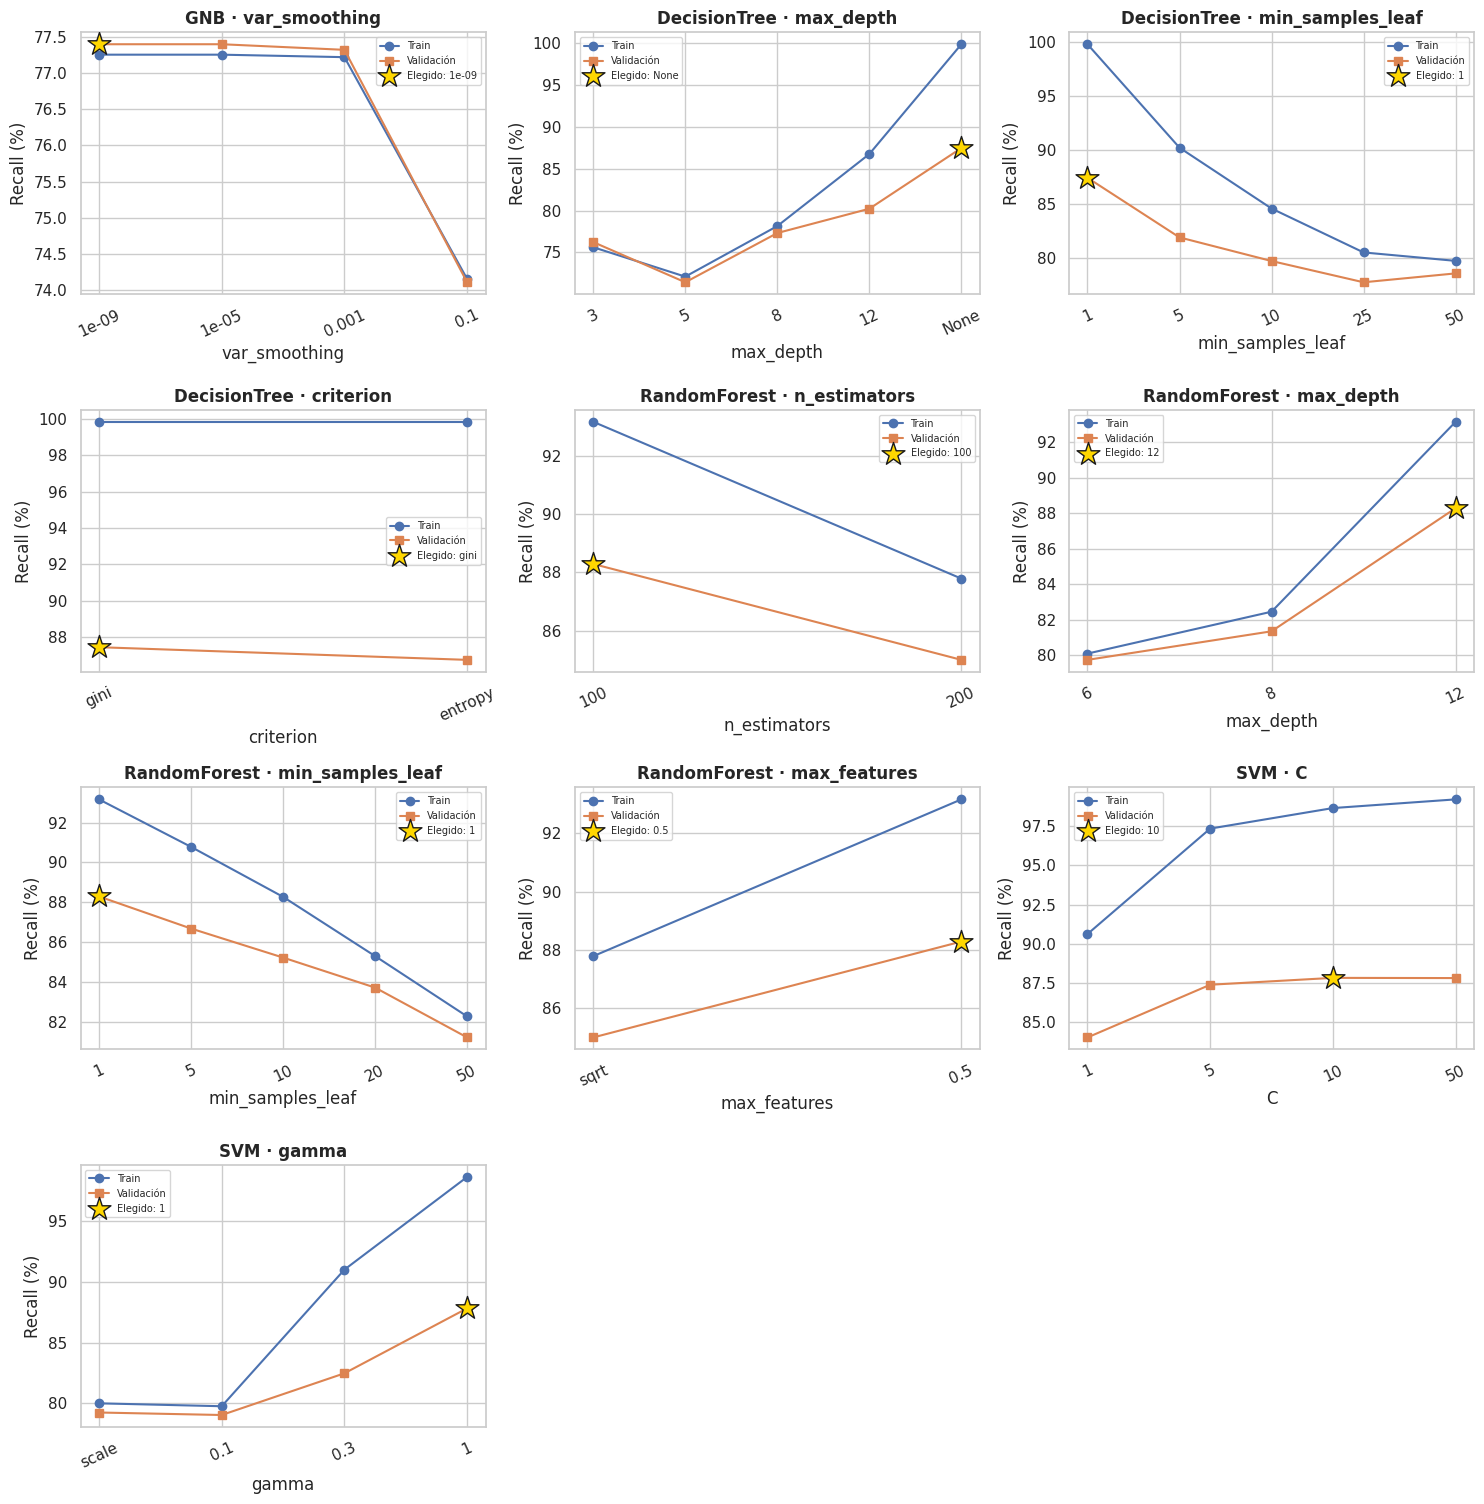

In [ ]:
METRICA = 'recall'

def clave_valor(x):
    return 'None' if x is None else str(x)

paneles = [(c, p, vals) for c, (_, _, grid, _) in config.items()
           for p, vals in grid.items() if len(vals) > 1]
ncol = 3
nfil = int(np.ceil(len(paneles) / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(5 * ncol, 3.8 * nfil))
axes = np.atleast_1d(axes).ravel()

for ax, (clave, p, vals) in zip(axes, paneles):
    d = res[res.modelo == clave]
    elegido = mejores[clave]['fila']['params'].get(p, 'NA')
    xs, ftr, fva = [], [], []
    for v in vals:
        sub = d[d['params'].apply(lambda q: clave_valor(q.get(p, 'NA')) == clave_valor(v))]
        if sub.empty:   # ese valor no salió en la búsqueda aleatoria
            continue
        r = sub.sort_values([METRICA, 'f1'], ascending=False).iloc[0]
        xs.append(clave_valor(v))
        ftr.append(r[f'{METRICA}_train'] * 100)
        fva.append(r[METRICA] * 100)
    x = np.arange(len(xs))
    ax.plot(x, ftr, marker='o', label='Train')
    ax.plot(x, fva, marker='s', label='Validación')
    if clave_valor(elegido) in xs:
        i = xs.index(clave_valor(elegido))
        ax.scatter([i], [fva[i]], marker='*', s=300, color='gold', edgecolor='k', zorder=5,
                   label=f'Elegido: {clave_valor(elegido)}')
    ax.set_xticks(x); ax.set_xticklabels(xs, rotation=25)
    ax.set_title(f'{NOMBRES[clave]} · {p}', fontweight='bold')
    ax.set_xlabel(p); ax.set_ylabel(f'{METRICA.capitalize()} (%)')
    ax.legend(fontsize=7)
for ax in axes[len(paneles):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

---
## 2. Clasificación multiclase: Bajo, Moderado, Alto

Se predicen tres clases (0 = Low, 1 = Moderate, 2 = High). Se comparan Random Forest y SVM. Ambos usan los hiperparámetros elegidos en la búsqueda binaria (sección 1.3); no se hizo una búsqueda específica para multiclase.

### 2.1 Etiquetas de tres clases y tamaño de cada conjunto


In [ ]:
y_multi = df['CKD_Risk'].map({'Low': 0, 'Moderate': 1, 'High': 2})


y_train_m = y_multi.loc[X_train.index]
y_val_m   = y_multi.loc[X_val.index]
y_test_m  = y_multi.loc[X_test.index]

pd.DataFrame({'train': y_train_m.value_counts().sort_index(),
              'val':   y_val_m.value_counts().sort_index(),
              'test':  y_test_m.value_counts().sort_index()})

,train,val,test
CKD_Risk,,,
0,190,72,53
1,6516,2164,2182
2,23294,7764,7765


In [ ]:
nombres_multi = {'rf': 'Random Forest', 'svm': 'SVM'}

modelos_multi = {}
for clave, nombre in nombres_multi.items():
    Modelo, fijos, _, _ = config[clave]
    params = mejores[clave]['fila']['params']
    modelos_multi[nombre] = Modelo(**fijos, **params).fit(X_train_p, y_train_m)

rf_multi = modelos_multi['Random Forest']
svm_multi = modelos_multi['SVM']

In [ ]:
for nombre, m in modelos_multi.items():
    p_tr = m.predict(X_train_p)
    print(nombre, '| F1 macro train:', round(f1_score(y_train_m, p_tr, average='macro'), 3),
          '| recall Low train:', round(recall_score(y_train_m, p_tr, average=None)[0], 3))

Random Forest | F1 macro train: 0.885 | recall Low train: 1.0
SVM | F1 macro train: 0.97 | recall Low train: 1.0


### 2.2 Métricas de los dos modelos

Accuracy, precisión macro, recall macro y F1 macro en validación y en test. El promedio macro da el mismo peso a cada clase, sin importar su tamaño.

In [ ]:
from sklearn.metrics import classification_report
conjuntos = [('Validación', X_val_p, y_val_m), ('Test', X_test_p, y_test_m)]

filas_metricas = []
for nombre, modelo in modelos_multi.items():
    for conjunto, X_c, y_c in conjuntos:
        y_pred = modelo.predict(X_c)
        filas_metricas.append({'Modelo': nombre,
                      'Conjunto': conjunto,
                      'Accuracy':  accuracy_score(y_c, y_pred),
                      'Precision': precision_score(y_c, y_pred, average='macro', zero_division=0),
                      'Recall':    recall_score(y_c, y_pred, average='macro'),
                      'F1':        f1_score(y_c, y_pred, average='macro')})

res_multi = pd.DataFrame(filas_metricas).set_index(['Modelo', 'Conjunto']).round(3)
res_multi

Accuracy  Precision  Recall     F1
Modelo        Conjunto                                      
Random Forest Validación     0.833      0.656   0.640  0.643
              Test           0.834      0.615   0.607  0.608
SVM           Validación     0.801      0.574   0.550  0.560
              Test           0.814      0.530   0.522  0.525

### 2.3 Reporte por clase y matriz de confusión en test

Precision, recall y F1 de cada clase. En cada fila de la matriz, los porcentajes suman 100 % y muestran qué predice el modelo para cada clase real.

,precision,recall,f1-score,support
Low,0.325000,0.245000,0.280000,53.000000
Moderate,0.604000,0.701000,0.649000,2182.000000
High,0.916000,0.876000,0.895000,7765.000000
accuracy,0.834000,0.834000,0.834000,0.834000
macro avg,0.615000,0.607000,0.608000,10000.000000
weighted avg,0.845000,0.834000,0.838000,10000.000000


,precision,recall,f1-score,support
Low,0.128000,0.113000,0.120000,53.000000
Moderate,0.580000,0.561000,0.570000,2182.000000
High,0.882000,0.890000,0.886000,7765.000000
accuracy,0.814000,0.814000,0.814000,0.814000
macro avg,0.530000,0.522000,0.525000,10000.000000
weighted avg,0.812000,0.814000,0.813000,10000.000000


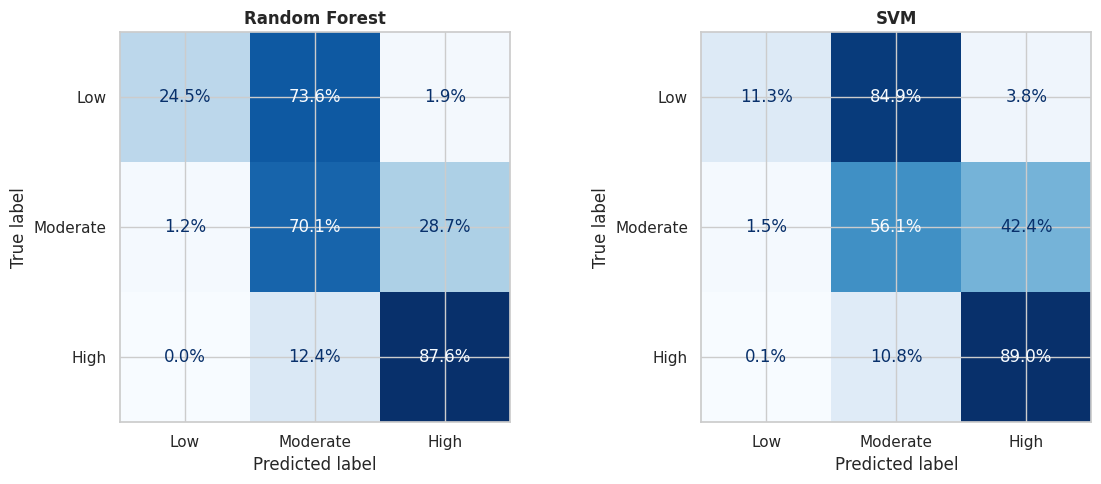

In [ ]:
nombres_clases = ['Low', 'Moderate', 'High']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nombre, modelo) in zip(axes, modelos_multi.items()):
    y_pred = modelo.predict(X_test_p)

    # Tabla con precision, recall y F1 de cada clase
    reporte = classification_report(y_test_m, y_pred, target_names=nombres_clases,
                                    output_dict=True, zero_division=0)
    display(pd.DataFrame(reporte).T.round(3).style.set_caption(nombre))

    # Matriz de confusión en porcentaje por clase real
    ConfusionMatrixDisplay.from_predictions(y_test_m, y_pred,
                                            display_labels=nombres_clases,
                                            normalize='true', values_format='.1%',
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre, fontweight='bold')

plt.tight_layout()
plt.show()

### 2.4 Curvas de aprendizaje multiclase: diferencia respecto a Random Forest

Se reentrenan Random Forest y SVM con 20 %, 40 %, 60 % y 80 % del entrenamiento (muestreo estratificado) y se evalúan en validación con métricas macro. El 100 % usa los modelos de la sección 2.2.

La gráfica muestra SVM − Random Forest en puntos porcentuales: valores negativos indican que SVM queda por debajo de Random Forest con ese tamaño de entrenamiento. Solo se comparan estos dos modelos, porque son los de la clasificación multiclase en este notebook.

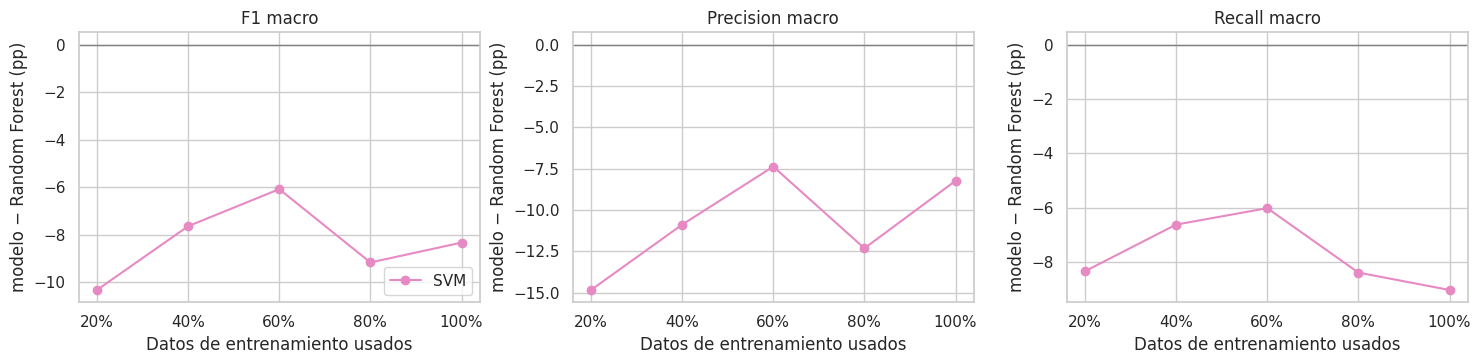

In [ ]:
FRACS_M = [0.2, 0.4, 0.6, 0.8, 1.0]
CLAVES_M = {'Random Forest': 'rf', 'SVM': 'svm'}
REF_M = 'Random Forest'
OTRO_M = 'SVM'

filas_m = []
for f in FRACS_M:
    if f < 1:
        Xs, _, ys, _ = train_test_split(X_train_p, y_train_m, train_size=f,
                                        stratify=y_train_m, random_state=42)
    else:
        Xs, ys = X_train_p, y_train_m
    for nombre, clave in CLAVES_M.items():
        if f == 1.0:
            m = modelos_multi[nombre]
        else:
            Modelo, fijos, _, _ = config[clave]
            m = Modelo(**fijos, **mejores[clave]['fila']['params']).fit(Xs, ys)
        p = m.predict(X_val_p)
        filas_m.append({'modelo': nombre, 'frac': f, 'pct': f'{int(f * 100)}%',
                        'F1 macro': f1_score(y_val_m, p, average='macro', zero_division=0),
                        'Precision macro': precision_score(y_val_m, p, average='macro', zero_division=0),
                        'Recall macro': recall_score(y_val_m, p, average='macro', zero_division=0)})

lc_m = pd.DataFrame(filas_m)
ref_m = lc_m[lc_m.modelo == REF_M].set_index('frac')
otro_m = lc_m[lc_m.modelo == OTRO_M].set_index('frac')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, m in zip(axes, ['F1 macro', 'Precision macro', 'Recall macro']):
    ax.plot(otro_m['pct'], (otro_m[m] - ref_m[m]) * 100, marker='o', color=PAL[3], label=OTRO_M)
    ax.axhline(0, color='gray', lw=1)
    ax.set_title(m); ax.set_xlabel('Datos de entrenamiento usados')
    ax.set_ylabel(f'modelo − {REF_M} (pp)')
axes[0].legend()
plt.tight_layout(); plt.show()

### 2.5 Comparación entre entrenamiento, validación y test

Esta gráfica compara el F1 macro y el recall de la clase Low de Random Forest y SVM en los tres conjuntos. Las barras de **entrenamiento** muestran qué tan bien aprende cada modelo los datos que ya vio. Las de **validación** muestran cómo se comporta con datos que no usó para entrenar. Las de **test** muestran el desempeño final.

Cómo leerla:
- **Entrenamiento frente a validación:** una diferencia grande indica sobreajuste. El modelo memoriza el entrenamiento y generaliza peor.
- **Validación frente a test:** deberían ser parecidas. Una diferencia grande sugiere que los hiperparámetros se ajustaron demasiado a validación, o que la partición no es representativa.
- **Recall de Low:** con pocos casos de Low en test, un cambio de unos pocos puntos puede no ser significativo.

El test se muestra solo para reportar el resultado final. No se usó para elegir los modelos, que ya se eligieron con validación en la sección 2.2.

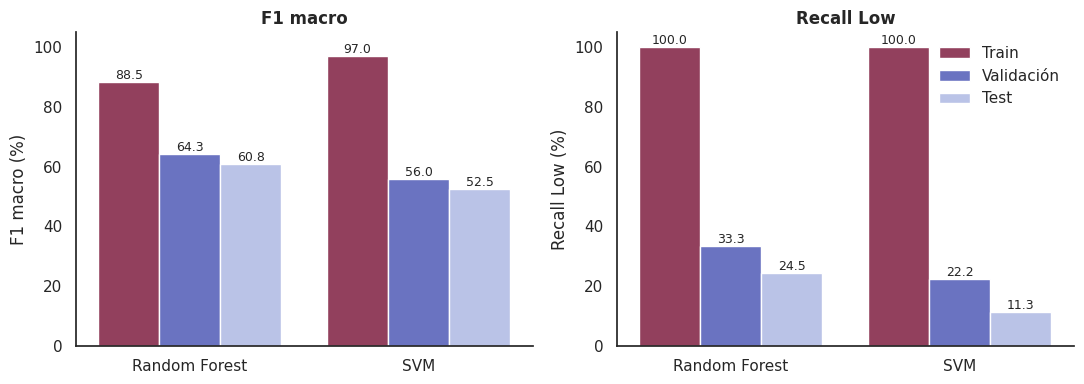

In [ ]:
filas = []
for nombre, m in modelos_multi.items():
    for conj, X_c, y_c in [('Train', X_train_p, y_train_m),
                           ('Validación', X_val_p, y_val_m),
                           ('Test', X_test_p, y_test_m)]:
        p = m.predict(X_c)
        filas.append({'Modelo': nombre, 'Conjunto': conj,
                      'F1 macro': f1_score(y_c, p, average='macro') * 100,
                      'Recall Low': recall_score(y_c, p, average=None, labels=[0, 1, 2])[0] * 100})
d = pd.DataFrame(filas)

paleta = ['#A03259', '#5B67D0', '#B3BEEE']
sns.set_theme(style='white')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['F1 macro', 'Recall Low']):
    sns.barplot(data=d, x='Modelo', y=col, hue='Conjunto', palette=paleta, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', fontsize=9)
    ax.set_ylim(0, 105); ax.set_xlabel(''); ax.set_ylabel(f'{col} (%)')
    ax.set_title(col, fontweight='bold')
    ax.get_legend().remove() if col == 'F1 macro' else ax.legend(title='', frameon=False)
sns.despine()
plt.tight_layout(); plt.show()

## 3. Experimento: balanceo por submuestreo

La clase Low tiene muchos menos casos que Moderado y Alto. Se comparan dos formas de entrenar:

- **Original:** entrenamiento completo con `class_weight='balanced'` (sección 2).
- **Balanceado:** se submuestrean Moderado y Alto hasta igualar el tamaño de Low, **sin** `class_weight`, para no compensar dos veces.

**Reglas del experimento**
- El submuestreo se hace **solo sobre el entrenamiento**. Validación y test no se tocan.
- Cada brazo elige sus hiperparámetros con **validación**, con la misma malla y el mismo criterio (F1 macro).
- El test se evalúa **una sola vez** al final.
- Ambos brazos salen de **la misma ejecución**, así que la comparación es válida.

### 3.1 Submuestreo del entrenamiento

Se toma una muestra aleatoria (semilla 42) de Moderado y de Alto con el mismo tamaño que Low. Validación y test no se modifican.

In [ ]:
rng = np.random.default_rng(42)
y_tr = np.asarray(y_train_m)

idx_por_clase = {c: np.where(y_tr == c)[0] for c in [0, 1, 2]}
n_low = min(len(v) for v in idx_por_clase.values())   # tamaño de Low en train

idx_bal = np.concatenate([rng.choice(v, n_low, replace=False) for v in idx_por_clase.values()])
rng.shuffle(idx_bal)

X_tr_bal, y_tr_bal = X_train_p[idx_bal], y_tr[idx_bal]

print('Train original  :', pd.Series(y_tr).value_counts().sort_index().to_dict())
print('Train balanceado:', pd.Series(y_tr_bal).value_counts().sort_index().to_dict())

Train original  : {0: 190, 1: 6516, 2: 23294}
Train balanceado: {0: 190, 1: 190, 2: 190}


### 3.2 Comparación de los brazos

Para cada modelo y cada brazo se calculan accuracy, F1 macro y recall de cada clase, en validación y en test.

In [ ]:
def evaluar(y_real, p):
    rec = recall_score(y_real, p, average=None, labels=[0, 1, 2], zero_division=0)
    return {'Accuracy': accuracy_score(y_real, p),
            'F1 macro': f1_score(y_real, p, average='macro'),
            'Recall Low': rec[0], 'Recall Moderate': rec[1], 'Recall High': rec[2]}

originales = {'RandomForest': rf_multi, 'SVM': svm_multi}   # ya tienen class_weight
modelos_bal = {}

filas = []
for nombre, clave in [('RandomForest', 'rf'), ('SVM', 'svm')]:
    Modelo, fijos, _, _ = config[clave]
    params = mejores[clave]['fila']['params']
    fijos_sin_peso = {k: v for k, v in fijos.items() if k != 'class_weight'}

    modelos_bal[nombre] = Modelo(**fijos_sin_peso, **params).fit(X_tr_bal, y_tr_bal)

    brazos = [('Original', originales[nombre]), ('Balanceado', modelos_bal[nombre])]
    for etiqueta, m in brazos:
        for conjunto, X_c, y_c in [('Validación', X_val_p, y_val_m), ('Test', X_test_p, y_test_m)]:
            filas.append({'Modelo': nombre, 'Train': etiqueta, 'Conjunto': conjunto,
                          **evaluar(y_c, m.predict(X_c))})

res_exp = pd.DataFrame(filas).set_index(['Modelo', 'Train', 'Conjunto'])
display((res_exp * 100).round(1))

Accuracy  F1 macro  Recall Low  \
Modelo       Train      Conjunto                                     
RandomForest Original   Validación      83.3      64.3        33.3   
                        Test            83.4      60.8        24.5   
             Balanceado Validación      71.2      48.6        79.2   
                        Test            71.9      48.0        77.4   
SVM          Original   Validación      80.1      56.0        22.2   
                        Test            81.4      52.5        11.3   
             Balanceado Validación      72.0      47.8        66.7   
                        Test            72.7      46.8        56.6   

                                    Recall Moderate  Recall High  
Modelo       Train      Conjunto                                  
RandomForest Original   Validación             71.7         87.0  
                        Test                   70.1         87.6  
             Balanceado Validación             55.7         75.5  
                        Test                   56.8         76.0  
SVM          Original   Validación             55.1         87.6  
                        Test                   56.1         89.0  
             Balanceado Validación             48.5         78.6  
                        Test                   50.1         79.2

### 3.3 Recall por clase en test

Comparación gráfica del recall de Low, Moderate y High para cada brazo.

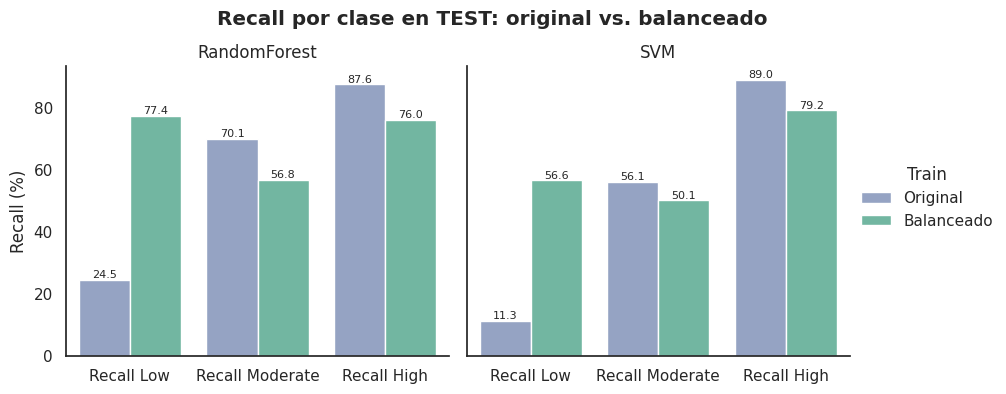

In [ ]:
test_exp = res_exp.xs('Test', level='Conjunto')[['Recall Low', 'Recall Moderate', 'Recall High']] * 100
test_exp = test_exp.reset_index().melt(id_vars=['Modelo', 'Train'], var_name='Clase', value_name='Recall (%)')

g = sns.catplot(data=test_exp, x='Clase', y='Recall (%)', hue='Train', col='Modelo', kind='bar',
                palette=['#8da0cb', '#66c2a5'], errorbar=None, height=4, aspect=1.1)
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', fontsize=8)
    ax.set_xlabel('')
g.set_titles('{col_name}')
g.figure.suptitle('Recall por clase en TEST: original vs. balanceado', y=1.04, fontweight='bold')
plt.show()

---
## 4. Conclusiones

### 4.1 Clasificación binaria (Alto frente al resto)

- **Random Forest** fue el mejor modelo en validación, con recall de Alto de 0,883 y F1 de 0,898.
- En test, Random Forest obtuvo recall de 0,887, precisión de 0,912, F1 de 0,899 y TNR de 0,703.
- **SVM** tuvo un recall en test ligeramente mayor (0,891), pero con F1 más bajo (0,885) y TNR de 0,573. Random Forest reconoce mejor a los pacientes de riesgo bajo.
- Hay sobreajuste en los modelos con más capacidad. La brecha de recall entre entrenamiento y validación es de 4,9 pp en Random Forest, 10,8 pp en SVM y 12,4 pp en el árbol de decisión. GNB casi no tiene brecha (-0,1 pp), pero tiene el recall más bajo (0,774).

### 4.2 Clasificación multiclase (Bajo, Moderado, Alto)

- Los resultados son débiles. En test, el F1 macro es de 0,608 para Random Forest y de 0,525 para SVM.
- El recall de Low en test es de 24,5 % para Random Forest (alrededor de 13 de 53 casos) y de 11,3 % para SVM (alrededor de 6 de 53).
- El sobreajuste es fuerte. En Random Forest, el F1 macro de entrenamiento es 0,885 y el de validación 0,643. En SVM, la diferencia es de 0,970 frente a 0,560.
- Los hiperparámetros de la multiclase vienen de la búsqueda binaria. Una búsqueda propia para multiclase podría cambiar estos resultados.

### 4.3 Experimento de balanceo (original frente a balanceado, en test)

| Modelo | Brazo | Recall Low | Recall Moderate | Recall High | F1 macro | Accuracy |
|---|---|---|---|---|---|---|
| Random Forest | Original | 24,5 | 70,1 | 87,6 | 60,8 | 83,4 |
| Random Forest | Balanceado | 77,4 | 56,8 | 76,0 | 48,0 | 71,9 |
| SVM | Original | 11,3 | 56,1 | 89,0 | 52,5 | 81,4 |
| SVM | Balanceado | 56,6 | 50,1 | 79,2 | 46,8 | 72,7 |

- El balanceo aumenta mucho el recall de Low: de 24,5 a 77,4 % en Random Forest, y de 11,3 a 56,6 % en SVM.
- El costo es alto. Bajan el recall de Moderate y de High, el F1 macro y la accuracy en ambos modelos.
- El balanceo sirve si el objetivo principal es detectar Low. Si importa mantener el desempeño general, el brazo original es mejor.

### 4.4 Limitaciones

- Los datos son sintéticos, así que los resultados describen este conjunto y no pacientes reales.
- Low tiene solo 53 casos en test. Las diferencias en recall de Low son grandes, pero seguimos con una sola partición y una sola semilla, y no medimos la variación entre corridas.
- En el brazo balanceado, los hiperparámetros vienen de la búsqueda binaria. Podrían no ser los mejores para ese conjunto.
- El brazo balanceado usa 190 casos por clase, así que descarta muchos casos de Moderado y de High.

### 4.5 Pasos siguientes

- Hacer una búsqueda propia para la multiclase y, para el brazo balanceado, una búsqueda sobre el conjunto balanceado.
- Repetir el experimento con varias semillas para medir la variación.
- Atender el sobreajuste de la multiclase, que es el problema más grave de los resultados.

# Avance #3

## 0. Preparación de los datos

### 0.1 Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, ParameterGrid, ParameterSampler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

In [ ]:
X = df[variables_seleccionadas].copy()
binarias = ['Hypertension', 'Diabetes', 'Family_History_CKD']
for col in binarias:
    X[col] = X[col].map({'No': 0, 'Yes': 1})

y = df['CKD_Risk_Score']

In [ ]:
estrato = df['CKD_Risk']
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20 , stratify=estrato, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=estrato.loc[X_dev.index], random_state=42)

print({'train': len(y_train), 'val': len(y_val), 'test': len(y_test)})

{'train': 30000, 'val': 10000, 'test': 10000}


In [ ]:
num_cols = [c for c in X.columns if c not in binarias + ['Smoking_Status']]
cat_cols = ['Smoking_Status']
procesamiento= ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_cols),
    ('bin', SimpleImputer(strategy='most_frequent'), binarias),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),

])
X_trainp= procesamiento.fit_transform(X_train)
X_valp= procesamiento.transform(X_val)
X_testp= procesamiento.transform(X_test)
print(X_trainp.shape , X_valp.shape, X_testp.shape)

(30000, 12) (10000, 12) (10000, 12)


In [ ]:

def reporte(nombre, y_real, pred):
    mse = mean_squared_error(y_real, pred)
    print(f"{nombre}: MSE {mse:.3f} | RMSE {np.sqrt(mse):.3f} | "f"MAE {mean_absolute_error(y_real, pred):.3f} | R2 {r2_score(y_real, pred):.3f}")

### 1. Árbol de decisión para regresión

In [ ]:
max_depth=[3, 5, 8, 12, 20, None]
leaf= [1, 5, 10, 25, 50]
filas = []
for d in max_depth:
    for m in leaf:
        arbol = DecisionTreeRegressor(max_depth=d, min_samples_leaf=m, random_state=42)
        arbol.fit(X_trainp, y_train)
        pred_tr = arbol.predict(X_trainp)
        pred_va = arbol.predict(X_valp)
        filas.append({'max_depth': d,
                      'min_samples_leaf': m,
                      'rmse_train': np.sqrt(mean_squared_error(y_train, pred_tr)),
                      'rmse_val':   np.sqrt(mean_squared_error(y_val, pred_va)),
                      'mae_val':    mean_absolute_error(y_val, pred_va)})

res_arbol = pd.DataFrame(filas)
res_arbol['brecha_rmse'] = res_arbol['rmse_val'] - res_arbol['rmse_train']
res_arbol = res_arbol.sort_values(['rmse_val', 'mae_val']).reset_index(drop=True)
res_arbol.head(10).round(3)

,max_depth,min_samples_leaf,rmse_train,rmse_val,mae_val,brecha_rmse
0,12.0,25,9.127,10.348,8.198,1.221
1,20.0,25,9.074,10.380,8.217,1.305
2,NaN,25,9.074,10.380,8.217,1.305
3,12.0,50,9.700,10.490,8.358,0.790
4,20.0,50,9.696,10.492,8.359,0.796
5,NaN,50,9.696,10.492,8.359,0.796
6,12.0,10,8.373,10.522,8.286,2.149
7,8.0,25,10.276,10.791,8.612,0.515
8,20.0,10,7.913,10.802,8.503,2.890
9,NaN,10,7.913,10.802,8.503,2.890


In [ ]:
mejor = res_arbol.iloc[0]
d_mejor = None if pd.isna(mejor['max_depth']) else int(mejor['max_depth'])

arbol_final = DecisionTreeRegressor(max_depth=d_mejor,
                                    min_samples_leaf=int(mejor['min_samples_leaf']),
                                    random_state=42)
arbol_final.fit(X_trainp, y_train)

(reporte('Árbol (train)', y_train, arbol_final.predict(X_trainp)))
reporte('Árbol (val)  ', y_val, arbol_final.predict(X_valp))

Árbol (train): MSE 83.307 | RMSE 9.127 | MAE 7.185 | R2 0.672


None

Árbol (val)  : MSE 107.077 | RMSE 10.348 | MAE 8.198 | R2 0.577


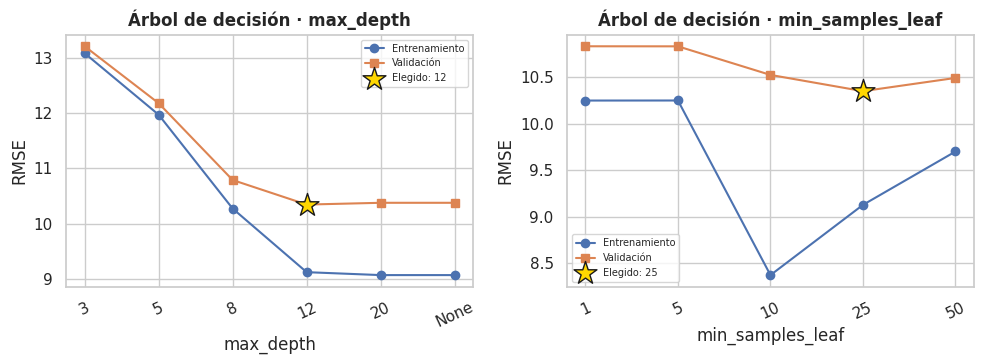

In [ ]:
def clave_valor(x):
    return 'None' if pd.isna(x) else str(int(x))

paneles = [('max_depth', max_depth), ('min_samples_leaf', leaf)]
elegido_params = {'max_depth': d_mejor, 'min_samples_leaf': int(mejor['min_samples_leaf'])}

ncol = 2
nfil = int(np.ceil(len(paneles) / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(5 * ncol, 3.8 * nfil))
axes = np.atleast_1d(axes).ravel()

for ax, (p, vals) in zip(axes, paneles):
    elegido = clave_valor(elegido_params[p])
    xs, rtr, rva = [], [], []
    for v in vals:
        sub = res_arbol[res_arbol[p].apply(lambda q: clave_valor(q) == clave_valor(v))]
        if sub.empty:
            continue
        r = sub.sort_values('rmse_val').iloc[0]
        xs.append(clave_valor(v)); rtr.append(r['rmse_train']); rva.append(r['rmse_val'])
    x = np.arange(len(xs))
    ax.plot(x, rtr, marker='o', label='Entrenamiento')
    ax.plot(x, rva, marker='s', label='Validación')
    if elegido in xs:
        i = xs.index(elegido)
        ax.scatter([i], [rva[i]], marker='*', s=300, color='gold', edgecolor='k', zorder=5,
                   label=f'Elegido: {elegido}')
    ax.set_xticks(x); ax.set_xticklabels(xs, rotation=25)
    ax.set_title(f'Árbol de decisión · {p}', fontweight='bold')
    ax.set_xlabel(p); ax.set_ylabel('RMSE')
    ax.legend(fontsize=7)
for ax in axes[len(paneles):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

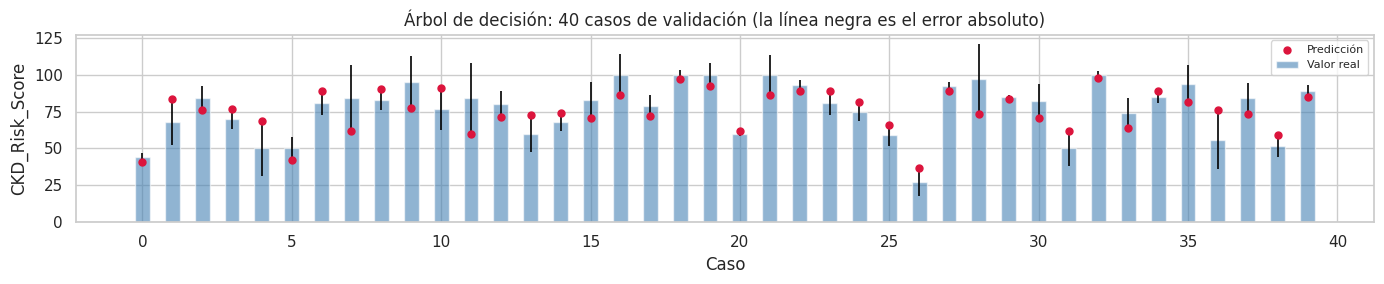

In [ ]:
rng = np.random.default_rng(42)
idx = rng.choice(len(y_val), size=40, replace=False)

X_40 = X_valp[idx]
real = y_val.to_numpy()[idx]
pred = arbol_final.predict(X_40)
err = np.abs(real - pred)

fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(np.arange(40), real, yerr=err, color='steelblue', alpha=0.6, width=0.5,
       error_kw={'ecolor': 'black', 'elinewidth': 1.2}, label='Valor real')
ax.scatter(np.arange(40), pred, color='crimson', zorder=5, s=25, label='Predicción')
ax.set_title('Árbol de decisión: 40 casos de validación (la línea negra es el error absoluto)')
ax.set_xlabel('Caso'); ax.set_ylabel('CKD_Risk_Score')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

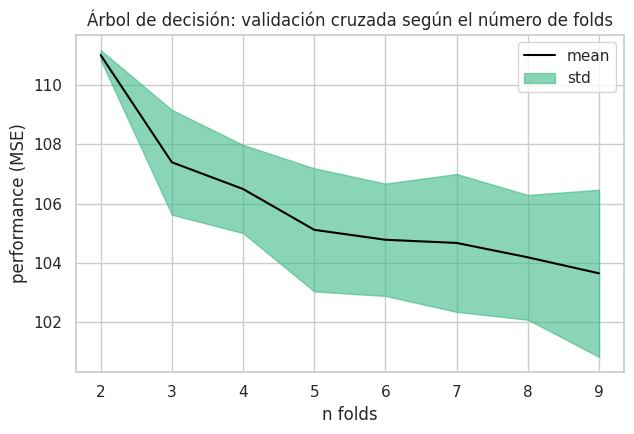

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

idx_dev = y_train.index.append(y_val.index)
X_dev = X.loc[idx_dev]
y_dev = df.loc[idx_dev, "CKD_Risk_Score"]

pipe_arbol = Pipeline([('pre', clone(procesamiento)),
                       ('arbol', DecisionTreeRegressor(max_depth=arbol_final.max_depth,
                                                       min_samples_leaf=arbol_final.min_samples_leaf,
                                                       random_state=42))])

ks = list(range(2, 10))
medias, desvs = [], []
for k in ks:
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    mse = -cross_val_score(pipe_arbol, X_dev, y_dev, cv=cv, scoring='neg_mean_squared_error')
    medias.append(mse.mean()); desvs.append(mse.std())

medias, desvs = np.array(medias), np.array(desvs)
color = tuple(np.random.default_rng().uniform(0.2, 0.8, 3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(ks, medias, color='black', label='mean')
ax.fill_between(ks, medias - desvs, medias + desvs, color=color, alpha=0.6, label='std')
ax.set_xlabel('n folds'); ax.set_ylabel('performance (MSE)')
ax.set_title("Árbol de decisión: validación cruzada según el número de folds")
ax.legend()
plt.tight_layout(); plt.show()

### 2. Random Forest para regresión

In [ ]:
def metricas_reg(y_real, pred):
    mse = mean_squared_error(y_real, pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_real, pred), 'R2': r2_score(y_real, pred)}

def buscar_reg(claves, cfg, X_fit, y_fit, X_v, y_v):
    filas, mejores = [], {}
    for nombre in claves:
        Modelo, fijos, grid, n_iter = cfg[nombre]
        combos = (list(ParameterGrid(grid)) if n_iter is None
                  else list(ParameterSampler(grid, n_iter=n_iter, random_state=42)))
        for i, params in enumerate(combos):
            m = Modelo(**fijos, **params).fit(X_fit, y_fit)
            fila = {'id': f'{nombre}_{i}', 'modelo': nombre, 'params': params,
                    **metricas_reg(y_v, m.predict(X_v)),
                    **{k + '_train': v for k, v in metricas_reg(y_fit, m.predict(X_fit)).items()}}
            filas.append(fila)
            if nombre not in mejores or fila['RMSE'] < mejores[nombre]['fila']['RMSE']:
                mejores[nombre] = {'fila': fila, 'modelo': m}
    return pd.DataFrame(filas), mejores


In [ ]:
config = {}
config['rf'] = (RandomForestRegressor, {'random_state': 42, 'n_jobs': -1},
                {'n_estimators': [100, 200],
                 'max_depth': [6, 8, 12, 20, None],
                 'min_samples_leaf': [1, 5, 10, 20, 50],
                 'max_features': ['sqrt', 0.5]},
                None)

t = time.time()
RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42).fit(X_trainp, y_train)
print(f'Un RF de 200 árboles tardó {time.time() - t:.1f} s')

Un RF de 200 árboles tardó 23.2 s


In [ ]:
res_rf, mejores_rf = buscar_reg(['rf'], config, X_trainp, y_train, X_valp, y_val)

top5 = res_rf.sort_values('RMSE').head(5)
print('Top 5: Random Forest')
display(top5[['params', 'RMSE', 'MAE', 'R2', 'RMSE_train']].round(3))

Top 5: Random Forest


,params,RMSE,MAE,R2,RMSE_train
83,"{'max_depth': None, 'max_features': 'sqrt', 'm...",9.319,7.468,0.657,7.192
63,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",9.321,7.473,0.657,7.191
82,"{'max_depth': None, 'max_features': 'sqrt', 'm...",9.328,7.470,0.657,7.205
62,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",9.329,7.478,0.656,7.206
43,"{'max_depth': 12, 'max_features': 'sqrt', 'min...",9.362,7.520,0.654,7.912


In [ ]:
f = mejores_rf['rf']['fila']
tabla_brecha_rf = pd.DataFrame([{
    'RMSE train': f['RMSE_train'], 'RMSE val': f['RMSE'],
    'brecha RMSE': f['RMSE'] - f['RMSE_train'],
    'R2 train': f['R2_train'], 'R2 val': f['R2'],
    'brecha R2': f['R2_train'] - f['R2']}], index=['Random Forest'])
display(tabla_brecha_rf.round(3))

,RMSE train,RMSE val,brecha RMSE,R2 train,R2 val,brecha R2
Random Forest,7.192,9.319,2.127,0.796,0.657,0.139


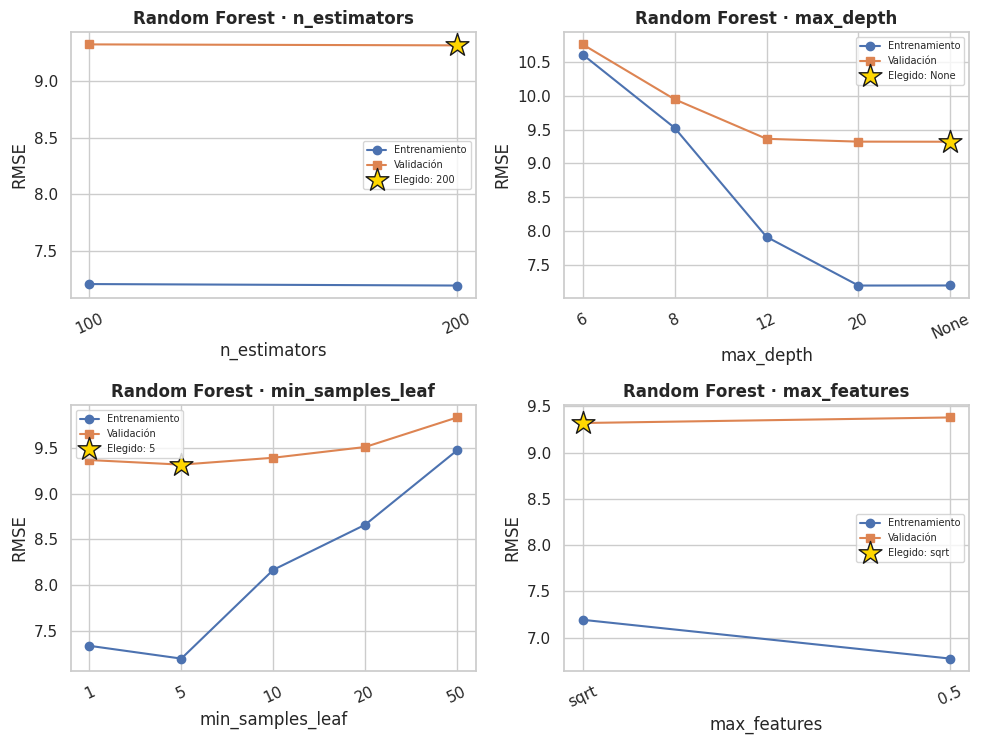

In [ ]:
def clave_valor(x):
    return 'None' if x is None else str(x)

grid_rf = config['rf'][2]
paneles = [(p, vals) for p, vals in grid_rf.items() if len(vals) > 1]
ncol = 2
nfil = int(np.ceil(len(paneles) / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(5 * ncol, 3.8 * nfil))
axes = np.atleast_1d(axes).ravel()

elegido_params = mejores_rf['rf']['fila']['params']
for ax, (p, vals) in zip(axes, paneles):
    elegido = clave_valor(elegido_params.get(p, 'NA'))
    xs, rtr, rva = [], [], []
    for v in vals:
        sub = res_rf[res_rf['params'].apply(lambda q: clave_valor(q.get(p, 'NA')) == clave_valor(v))]
        if sub.empty:
            continue
        r = sub.sort_values('RMSE').iloc[0]
        xs.append(clave_valor(v)); rtr.append(r['RMSE_train']); rva.append(r['RMSE'])
    x = np.arange(len(xs))
    ax.plot(x, rtr, marker='o', label='Entrenamiento')
    ax.plot(x, rva, marker='s', label='Validación')
    if elegido in xs:
        i = xs.index(elegido)
        ax.scatter([i], [rva[i]], marker='*', s=300, color='gold', edgecolor='k', zorder=5,
                   label=f'Elegido: {elegido}')
    ax.set_xticks(x); ax.set_xticklabels(xs, rotation=25)
    ax.set_title(f'Random Forest · {p}', fontweight='bold')
    ax.set_xlabel(p); ax.set_ylabel('RMSE')
    ax.legend(fontsize=7)
for ax in axes[len(paneles):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

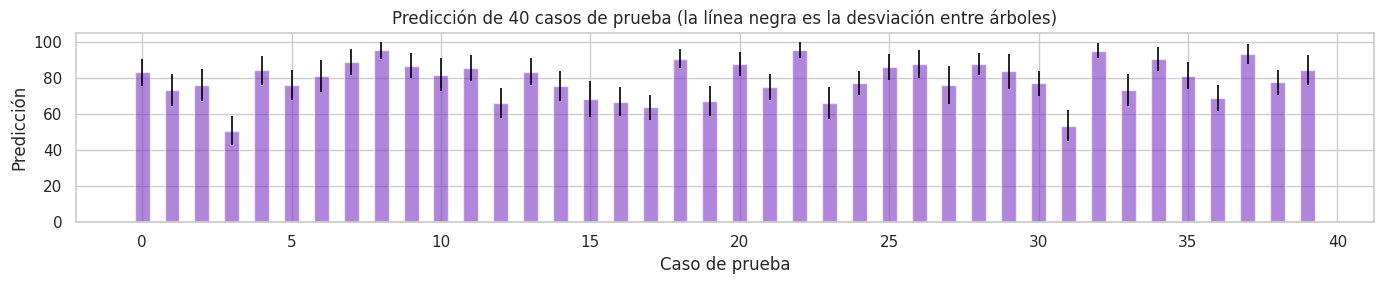

In [ ]:
rf_final = mejores_rf['rf']['modelo']

rng = np.random.default_rng(42)
idx = rng.choice(len(y_test), size=40, replace=False)
X_te = X_testp[idx]

# predicción de cada árbol del bosque para esos 40 casos
preds = np.stack([arbol.predict(X_te) for arbol in rf_final.estimators_])
media = preds.mean(axis=0)
desv = preds.std(axis=0)

color = tuple(np.random.default_rng().uniform(0.2, 0.8, 3))   # color aleatorio

fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(np.arange(40), media, yerr=desv, color=color, alpha=0.6, width=0.5,
       error_kw={'ecolor': 'black', 'elinewidth': 1.2})
ax.set_title('Predicción de 40 casos de prueba (la línea negra es la desviación entre árboles)')
ax.set_xlabel('Caso de prueba'); ax.set_ylabel('Predicción')
plt.tight_layout(); plt.show()

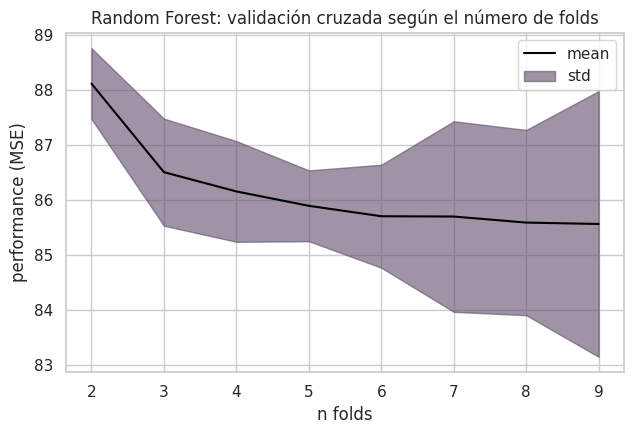

In [ ]:
params_rf = mejores_rf['rf']['fila']['params']
fijos_rf = config['rf'][1]

# El preprocesamiento va dentro del pipeline: en cada fold se ajusta solo con ese train
pipe_rf = Pipeline([('pre', clone(procesamiento)),
                    ('rf', RandomForestRegressor(**fijos_rf, **params_rf))])

ks = list(range(2, 10))
medias, desvs = [], []
for k in ks:
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    mse = -cross_val_score(pipe_rf, X_dev, y_dev, cv=cv, scoring='neg_mean_squared_error')
    medias.append(mse.mean()); desvs.append(mse.std())

medias, desvs = np.array(medias), np.array(desvs)
color = tuple(np.random.default_rng().uniform(0.2, 0.8, 3))   # color aleatorio

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(ks, medias, color='black', label='mean')
ax.fill_between(ks, medias - desvs, medias + desvs, color=color, alpha=0.6, label='std')
ax.set_xlabel('n folds'); ax.set_ylabel('performance (MSE)')
ax.set_title("Random Forest: validación cruzada según el número de folds")
ax.legend()
plt.tight_layout(); plt.show()

### 3. SVR (Support Vector Regression)

In [ ]:
# Desviación estándar del score:
# se usa para fijar epsilon
sd_y = float(y_train.std())
print('Desviación estándar del score:', round(sd_y, 2))
print('Epsilon 10 %:', round(0.10 * sd_y, 2))

Desviación estándar del score: 15.94
Epsilon 10 %: 1.59


In [ ]:
# Configuración de la grilla para SVR
config["svr"] = (SVR, {"kernel": "rbf"},
                 {"C": [1, 10, 50],
                  "gamma": ["scale", 0.1],
                  "epsilon": [round(0.10 * sd_y, 2)]},
                 None)

t = time.time()
SVR(kernel="rbf", C=50).fit(X_trainp, y_train)
print(f"Un SVR con {len(y_train)} filas demoró {time.time() - t:.1f} s")

Un SVR con 30000 filas demoró 112.2 s


In [ ]:
res_svr, mejores_svr = buscar_reg(["svr"], config, X_trainp, y_train, X_valp, y_val)

top5 = res_svr.sort_values("RMSE").head(5)
print("Top 5: SVR")
display(top5[["params", "RMSE", "MAE", "R2", "RMSE_train"]].round(3))

Top 5: SVR


,params,RMSE,MAE,R2,RMSE_train
3,"{'C': 10, 'epsilon': 1.59, 'gamma': 0.1}",9.613,7.572,0.635,9.379
2,"{'C': 10, 'epsilon': 1.59, 'gamma': 'scale'}",9.627,7.581,0.634,9.295
5,"{'C': 50, 'epsilon': 1.59, 'gamma': 0.1}",9.669,7.609,0.631,9.230
0,"{'C': 1, 'epsilon': 1.59, 'gamma': 'scale'}",9.678,7.657,0.630,9.546
1,"{'C': 1, 'epsilon': 1.59, 'gamma': 0.1}",9.687,7.669,0.630,9.589


In [ ]:
svr_final = mejores_svr["svr"]["modelo"]
print("Mejores hiperparámetros:", mejores_svr["svr"]["fila"]["params"])

reporte("SVR en train", y_train, svr_final.predict(X_trainp))
reporte("SVR en val", y_val, svr_final.predict(X_valp))

Mejores hiperparámetros: {'C': 10, 'epsilon': 1.59, 'gamma': 0.1}
SVR en train: MSE 87.966 | RMSE 9.379 | MAE 7.279 | R2 0.654
SVR en val: MSE 92.409 | RMSE 9.613 | MAE 7.572 | R2 0.635


In [ ]:
f = mejores_svr["svr"]["fila"]
tabla_brecha_svr = pd.DataFrame([{
    "RMSE train": f["RMSE_train"], "RMSE val": f["RMSE"],
    "brecha RMSE": f["RMSE"] - f["RMSE_train"],
    "R2 train": f["R2_train"], "R2 val": f["R2"],
    "brecha R2": f["R2_train"] - f["R2"]}], index=["SVR"])
display(tabla_brecha_svr.round(3))

,RMSE train,RMSE val,brecha RMSE,R2 train,R2 val,brecha R2
SVR,9.379,9.613,0.234,0.654,0.635,0.018


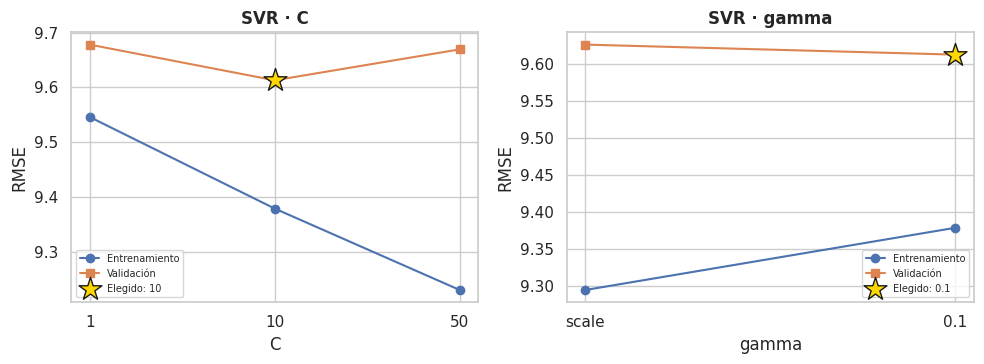

In [ ]:
def clave_valor(x):
    return "None" if x is None else str(x)

grid_svr = config["svr"][2]
paneles = [(p, vals) for p, vals in grid_svr.items() if len(vals) > 1]
fig, axes = plt.subplots(1, len(paneles), figsize=(5 * len(paneles), 3.8))
axes = np.atleast_1d(axes).ravel()

elegido_params = mejores_svr["svr"]["fila"]["params"]
for ax, (p, vals) in zip(axes, paneles):
    elegido = clave_valor(elegido_params.get(p, "NA"))
    xs, rtr, rva = [], [], []
    for v in vals:
        sub = res_svr[res_svr["params"].apply(lambda q: clave_valor(q.get(p, "NA")) == clave_valor(v))]
        if sub.empty:
            continue
        r = sub.sort_values("RMSE").iloc[0]
        xs.append(clave_valor(v)); rtr.append(r["RMSE_train"]); rva.append(r["RMSE"])
    x = np.arange(len(xs))
    ax.plot(x, rtr, marker="o", label="Entrenamiento")
    ax.plot(x, rva, marker="s", label="Validación")
    if elegido in xs:
        i = xs.index(elegido)
        ax.scatter([i], [rva[i]], marker="*", s=300, color="gold", edgecolor="k", zorder=5,
                   label=f"Elegido: {elegido}")
    ax.set_xticks(x); ax.set_xticklabels(xs)
    ax.set_title(f"SVR · {p}", fontweight="bold")
    ax.set_xlabel(p); ax.set_ylabel("RMSE")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:

idx_dev = y_train.index.append(y_val.index)
X_dev = X.loc[idx_dev]
y_dev = df.loc[idx_dev, "CKD_Risk_Score"]
print(y_dev.describe().round(2))

count    40000.00
mean        76.89
std         15.93
min          9.00
25%         66.00
50%         78.00
75%         90.00
max        100.00
Name: CKD_Risk_Score, dtype: float64


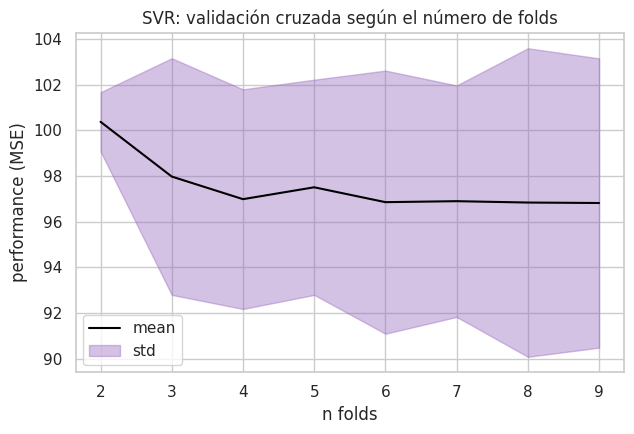

In [ ]:
params_svr = mejores_svr["svr"]["fila"]["params"]

# Submuestra de 6.000 filas de train + validación
X_cv, _, y_cv, _ = train_test_split(X_dev, y_dev, train_size=6000,
                                    stratify=estrato.loc[X_dev.index], random_state=42)


pipe_svr = Pipeline([("pre", clone(procesamiento)),
                     ("svr", SVR(kernel="rbf", **params_svr))])

ks = list(range(2, 10))
medias, desvs = [], []
for k in ks:
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    mse = -cross_val_score(pipe_svr, X_cv, y_cv, cv=cv, scoring="neg_mean_squared_error")
    medias.append(mse.mean()); desvs.append(mse.std())

medias, desvs = np.array(medias), np.array(desvs)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(ks, medias, color="black", label="mean")
ax.fill_between(ks, medias - desvs, medias + desvs, color="tab:purple", alpha=0.4, label="std")
ax.set_xlabel("n folds"); ax.set_ylabel("performance (MSE)")
ax.set_title("SVR: validación cruzada según el número de folds")
ax.legend()
plt.tight_layout(); plt.show()

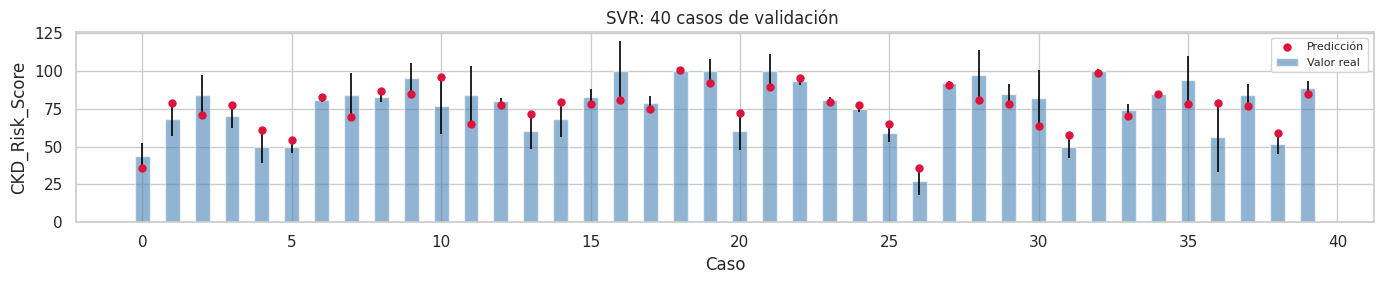

In [ ]:
rng = np.random.default_rng(42)
idx = rng.choice(len(y_val), size=40, replace=False)
real_40 = y_val.iloc[idx].values
pred_40 = svr_final.predict(X_valp[idx])
error_40 = np.abs(real_40 - pred_40)

x = np.arange(40)
fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(x, real_40, yerr=error_40, color="steelblue", alpha=0.6, width=0.5,
       error_kw={"ecolor": "black", "elinewidth": 1.2}, label="Valor real")
ax.scatter(x, pred_40, color="crimson", s=25, zorder=3, label="Predicción")
ax.set_title("SVR: 40 casos de validación ")
ax.set_xlabel("Caso"); ax.set_ylabel("CKD_Risk_Score")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4. Evaluación final en test

Primero se comparan los tres modelos en validación (RMSE, y MAE como desempate) y se eligen los dos mejores. Solo esos dos se evalúan en test, una sola vez.

In [ ]:
modelos = {"Árbol de decisión": arbol_final,
           "Random Forest": rf_final,
           "SVR": svr_final}

filas = []
for nombre in modelos:
    m = metricas_reg(y_val, modelos[nombre].predict(X_valp))
    filas.append({"modelo": nombre, "RMSE": m["RMSE"], "MAE": m["MAE"], "R2": m["R2"]})

tabla_val = pd.DataFrame(filas).sort_values(["RMSE", "MAE"]).reset_index(drop=True)
display(tabla_val.round(3))

finalistas = list(tabla_val["modelo"][:2])
print("Finalistas:", finalistas)

,modelo,RMSE,MAE,R2
0,Random Forest,9.319,7.468,0.657
1,SVR,9.613,7.572,0.635
2,Árbol de decisión,10.348,8.198,0.577


Finalistas: ['Random Forest', 'SVR']


In [ ]:
pred_test = {}
filas = []
for nombre in finalistas:
    pred_test[nombre] = modelos[nombre].predict(X_testp)
    m = metricas_reg(y_test, pred_test[nombre])
    filas.append({"modelo": nombre, "RMSE test": m["RMSE"], "MAE test": m["MAE"], "R2 test": m["R2"]})

tabla_test = pd.DataFrame(filas)
display(tabla_test.round(3))

,modelo,RMSE test,MAE test,R2 test
0,Random Forest,9.304,7.446,0.661
1,SVR,9.632,7.582,0.637


#Comparacion final entre modelos


In [ ]:
sns.set_theme(style="whitegrid")
COL = {"Árbol de decisión": "#E07B39", "Random Forest": "#2E8B57", "SVR": "#5B67D0"}
nombres_reg = list(modelos)

p_tr = {n: m.predict(X_trainp) for n, m in modelos.items()}
p_va = {n: m.predict(X_valp) for n, m in modelos.items()}
p_te = {n: m.predict(X_testp) for n, m in modelos.items()}

In [ ]:
filas = []
for n in nombres_reg:
    mv, mt, mtr = metricas_reg(y_val, p_va[n]), metricas_reg(y_test, p_te[n]), metricas_reg(y_train, p_tr[n])
    filas.append({"Modelo": n,
                  "RMSE train": mtr["RMSE"], "RMSE val": mv["RMSE"],
                  "Brecha RMSE": mv["RMSE"] - mtr["RMSE"],
                  "MAE val": mv["MAE"], "R² val": mv["R2"],
                  "RMSE test": mt["RMSE"] if n in finalistas else np.nan,
                  "MAE test": mt["MAE"] if n in finalistas else np.nan,
                  "R² test": mt["R2"] if n in finalistas else np.nan})
tabla_comp = pd.DataFrame(filas).set_index("Modelo")
display(tabla_comp.round(3))


,RMSE train,RMSE val,Brecha RMSE,MAE val,R² val,RMSE test,MAE test,R² test
Modelo,,,,,,,,
Árbol de decisión,9.127,10.348,1.221,8.198,0.577,NaN,NaN,NaN
Random Forest,7.192,9.319,2.127,7.468,0.657,9.304,7.446,0.661
SVR,9.379,9.613,0.234,7.572,0.635,9.632,7.582,0.637


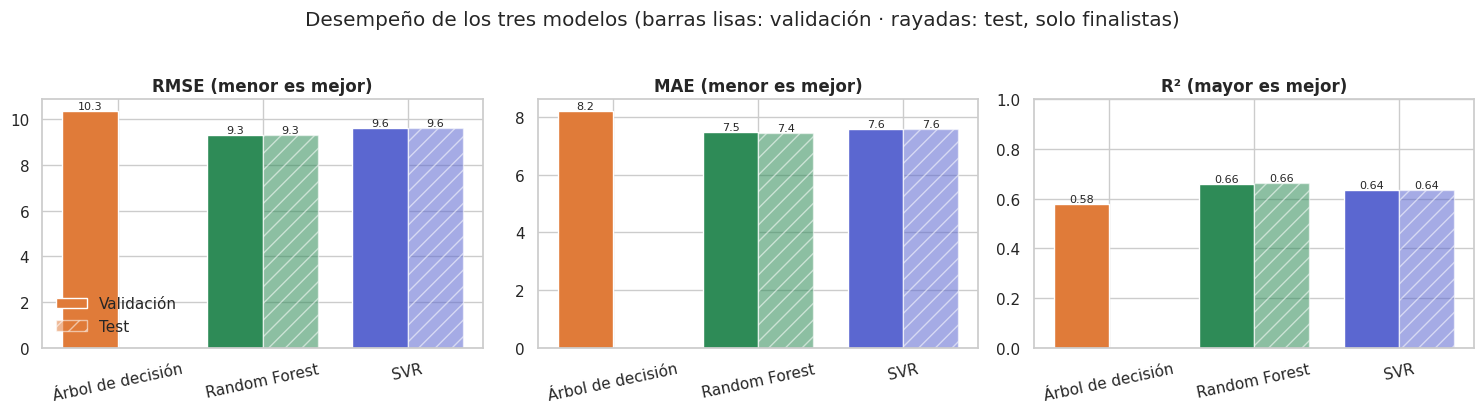

In [ ]:
metricas_plot = [("RMSE", "RMSE (menor es mejor)"), ("MAE", "MAE (menor es mejor)"), ("R2", "R² (mayor es mejor)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ancho = 0.38
for ax, (m, titulo) in zip(axes, metricas_plot):
    x = np.arange(len(nombres_reg))
    v_val = [metricas_reg(y_val, p_va[n])[m] for n in nombres_reg]
    v_te = [metricas_reg(y_test, p_te[n])[m] if n in finalistas else np.nan for n in nombres_reg]
    b1 = ax.bar(x - ancho / 2, v_val, ancho, color=[COL[n] for n in nombres_reg], label="Validación")
    b2 = ax.bar(x + ancho / 2, v_te, ancho, color=[COL[n] for n in nombres_reg], alpha=0.55, hatch="//", label="Test")
    for barras, vals in ((b1, v_val), (b2, v_te)):
        for b, v in zip(barras, vals):
            if not np.isnan(v):
                ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}" if m == "R2" else f"{v:.1f}",
                        ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(nombres_reg, rotation=12)
    ax.set_title(titulo, fontweight="bold")
    if m == "R2":
        ax.set_ylim(0, 1)
axes[0].legend(frameon=False)
fig.suptitle("Desempeño de los tres modelos (barras lisas: validación · rayadas: test, solo finalistas)", y=1.03)
plt.tight_layout(); plt.show()


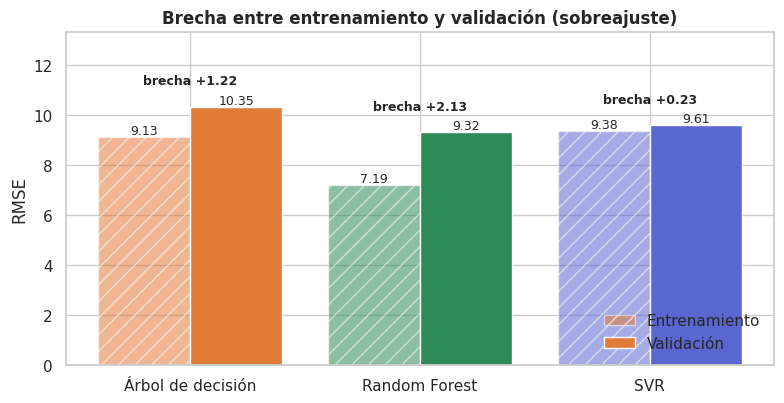

In [ ]:
rmse_tr = [metricas_reg(y_train, p_tr[n])["RMSE"] for n in nombres_reg]
rmse_va = [metricas_reg(y_val, p_va[n])["RMSE"] for n in nombres_reg]
x = np.arange(len(nombres_reg))

fig, ax = plt.subplots(figsize=(8, 4.2))
b1 = ax.bar(x - 0.2, rmse_tr, 0.4, color=[COL[n] for n in nombres_reg], alpha=0.55, hatch="//", label="Entrenamiento")
b2 = ax.bar(x + 0.2, rmse_va, 0.4, color=[COL[n] for n in nombres_reg], label="Validación")
for i, (a, b) in enumerate(zip(rmse_tr, rmse_va)):
    ax.text(i - 0.2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=9)
    ax.text(i + 0.2, b, f"{b:.2f}", ha="center", va="bottom", fontsize=9)
    ax.text(i, max(a, b) + 0.9, f"brecha {b - a:+.2f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(nombres_reg)
ax.set_ylabel("RMSE"); ax.set_ylim(0, max(rmse_va) + 3)
ax.set_title("Brecha entre entrenamiento y validación (sobreajuste)", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()


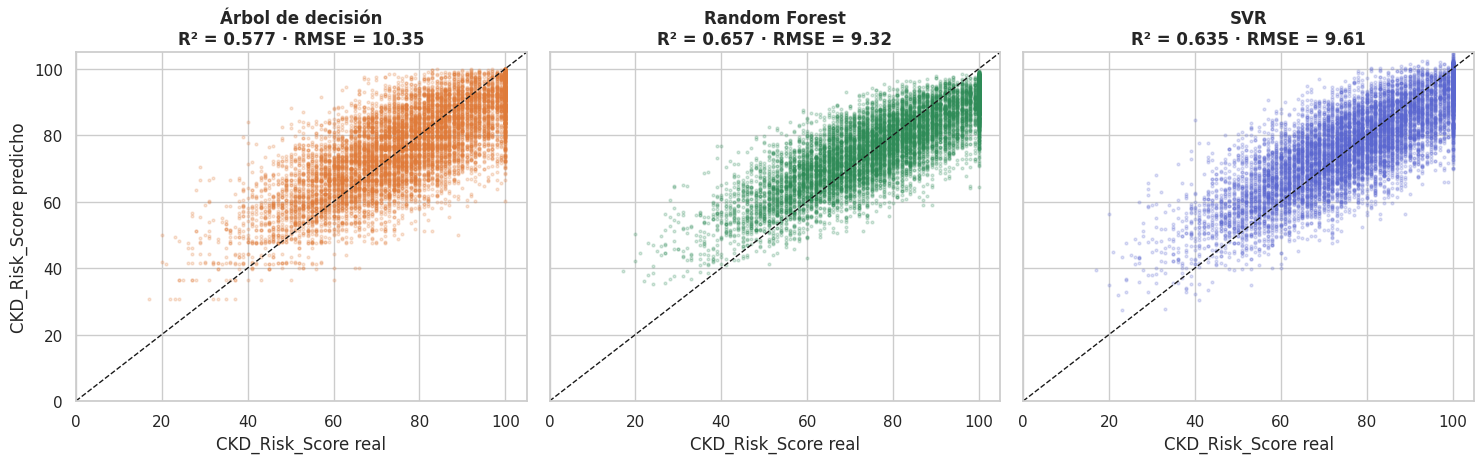

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
lim = [min(y_val.min(), 0), 105]
for ax, n in zip(axes, nombres_reg):
    ax.scatter(y_val, p_va[n], s=4, alpha=0.2, color=COL[n])
    ax.plot(lim, lim, "k--", lw=1)
    r = metricas_reg(y_val, p_va[n])
    ax.set_title(f"{n}\nR² = {r['R2']:.3f} · RMSE = {r['RMSE']:.2f}", fontweight="bold")
    ax.set_xlabel("CKD_Risk_Score real")
    ax.set_xlim(lim); ax.set_ylim(lim)
axes[0].set_ylabel("CKD_Risk_Score predicho")
plt.tight_layout(); plt.show()


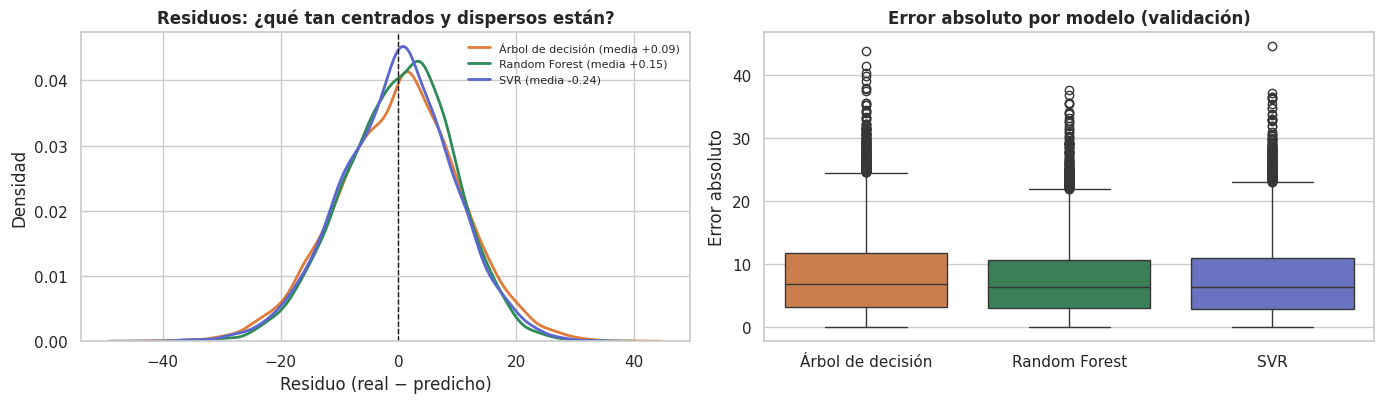

In [ ]:
res_va = {n: y_val.to_numpy() - p_va[n] for n in nombres_reg}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for n in nombres_reg:
    sns.kdeplot(res_va[n], ax=axes[0], color=COL[n], lw=2, label=f"{n} (media {res_va[n].mean():+.2f})")
axes[0].axvline(0, color="k", lw=1, ls="--")
axes[0].set_xlabel("Residuo (real − predicho)"); axes[0].set_ylabel("Densidad")
axes[0].set_title("Residuos: ¿qué tan centrados y dispersos están?", fontweight="bold")
axes[0].legend(frameon=False, fontsize=8)

err_abs = pd.DataFrame({n: np.abs(res_va[n]) for n in nombres_reg}).melt(var_name="Modelo", value_name="Error absoluto")
sns.boxplot(data=err_abs, x="Modelo", y="Error absoluto", hue="Modelo", palette=COL, legend=False, ax=axes[1])
axes[1].set_xlabel(""); axes[1].set_title("Error absoluto por modelo (validación)", fontweight="bold")
plt.tight_layout(); plt.show()
